# NYC Urban Growth & Road Safety
## Data Engineering and Visualization — Milestone 1


### 1.1 Project Overview

New York City's housing development and transportation systems are
closely connected. Understanding their relationships can help city
planners identify neighborhoods requiring infrastructure improvements.

This project investigates geographic and temporal relationships between
affordable housing development and serious traffic injuries across
New York City.

### 1.2 Research Objective

To explore whether areas experiencing greater affordable housing
production also exhibit different patterns of serious traffic injuries.

The project examines associations rather than assuming causal
relationships.

### 1.3 Selected Datasets

**Dataset 1: Affordable Housing Production by Building (H2)**

Source:
https://data.cityofnewyork.us/d/hg8x-zxpr

**Dataset 2: Serious Injury Response, Tracking & Analysis (SIRTA) (T4)**

Source:
https://data.cityofnewyork.us/d/xeqp-qz8h

### 1.4 Project Methodology

The project follows these stages:

1. Dataset loading and inspection.
2. Exploratory Data Analysis (EDA).
3. Pre-integration data cleaning.
4. Dataset integration.
5. Post-integration cleaning.
6. Research questions and visualizations.
7. Interactive website development.
8. Findings, limitations, and conclusions.

In [1]:
# =====================================================
# 1. IMPORT REQUIRED LIBRARIES
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
from pathlib import Path

# Configure Pandas display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

# Configure visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!



## 2. Dataset Acquisition and Loading

Two datasets were selected from NYC Open Data:

1. Affordable Housing Production by Building (hg8x-zxpr)
2. Serious Injury Response, Tracking & Analysis Program (xeqp-qz8h)

The project description provides examples of retrieving datasets
directly through the NYC Open Data API.

For this project, the official datasets were downloaded as CSV files
and loaded locally using Pandas.

This method was selected after a direct CSV download request
returned HTTP 503 (Service Unavailable).

The original downloaded files are preserved without modification,
and all subsequent cleaning is performed on DataFrame copies.

**Reproducibility:**

The files `housing.csv` and `transportation.csv` must be available
in the Colab `/content` directory before executing the notebook.

**Source Links:**

- https://data.cityofnewyork.us/d/hg8x-zxpr
- https://data.cityofnewyork.us/d/xeqp-qz8h


In [70]:

# =====================================================
# 2 & 3. LOAD AND VALIDATE THE TWO NYC OPEN DATA DATASETS
# =====================================================

import pandas as pd
from pathlib import Path

# Official NYC Open Data identifiers
HOUSING_DATASET_ID = "hg8x-zxpr"
TRANSPORT_DATASET_ID = "xeqp-qz8h"

HOUSING_SOURCE_URL = (
    f"https://data.cityofnewyork.us/d/{HOUSING_DATASET_ID}"
)

TRANSPORT_SOURCE_URL = (
    f"https://data.cityofnewyork.us/d/{TRANSPORT_DATASET_ID}"
)

# Load locally downloaded official CSV files
DATA_DIR = Path("/content")

housing_path = DATA_DIR / "Affordable_Housing_Production_by_Building_20261107.csv"
transport_path = DATA_DIR / "Serious_Injury_Response,_Tracking_&_Analysis_Program_(SIRTA)_20261107.csv"

for path in [housing_path, transport_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required file: {path.name}"
        )

df_housing = pd.read_csv(
    housing_path, low_memory=False
)

df_transport = pd.read_csv(
    transport_path, low_memory=False
)

# Verify important fields
required_housing = {
    "Project ID",
    "Project Completion Date",
    "Postcode",
    "Borough",
    "All Counted Units",
    "Reporting Construction Type"
}

required_transport = {
    "Collision ID",
    "Crash Date",
    "ZipCode",
    "Crash Borough",
    "Total Severe Injuries",
    "Total Fatalities"
}

assert required_housing.issubset(df_housing.columns)
assert required_transport.issubset(df_transport.columns)

assert df_housing.shape[1] >= 9
assert df_transport.shape[1] >= 9

print("Datasets loaded and validated successfully!")

print("Housing:", df_housing.shape)
print("Transportation:", df_transport.shape)

print("\nOfficial sources:")
print(HOUSING_SOURCE_URL)
print(TRANSPORT_SOURCE_URL)


Datasets loaded and validated successfully!
Housing: (9551, 41)
Transportation: (13754, 23)

Official sources:
https://data.cityofnewyork.us/d/hg8x-zxpr
https://data.cityofnewyork.us/d/xeqp-qz8h


In [4]:
# =====================================================
# 4. VALIDATE DATASET DIMENSIONS
# =====================================================

print("=" * 60)
print("DATASET DIMENSION VALIDATION")
print("=" * 60)

datasets = {
    "Housing": df_housing,
    "Transportation": df_transport
}

for name, df in datasets.items():

    rows, columns = df.shape

    print(f"\n{name} Dataset")
    print("-" * 40)

    print(f"Number of Rows: {rows:,}")
    print(f"Number of Columns: {columns}")

    if rows > 0 and columns >= 9:
        print("Status: PASSED")
    else:
        print("Status: FAILED - Dataset requires investigation")

    print(f"Memory Usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

DATASET DIMENSION VALIDATION

Housing Dataset
----------------------------------------
Number of Rows: 9,551
Number of Columns: 41
Status: PASSED
Memory Usage: 8.82 MB

Transportation Dataset
----------------------------------------
Number of Rows: 13,754
Number of Columns: 23
Status: PASSED
Memory Usage: 6.60 MB


In [5]:
# =====================================================
# 5. DATASET PREVIEW
# =====================================================

print("=" * 60)
print("HOUSING DATASET - FIRST 5 ROWS")
print("=" * 60)

display(df_housing.head())

print("\n" + "=" * 60)
print("TRANSPORTATION DATASET - FIRST 5 ROWS")
print("=" * 60)

display(df_transport.head())

HOUSING DATASET - FIRST 5 ROWS


,Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,BIN,Community Board,Council District,Census Tract,NTA - Neighborhood Tabulation Area,Latitude,Longitude,Latitude (Internal),Longitude (Internal),Building Completion Date,Reporting Construction Type,Extended Affordability Only,Prevailing Wage Status,Extremely Low Income Units,Very Low Income Units,Low Income Units,Moderate Income Units,Middle Income Units,Other Income Units,Studio Units,1-BR Units,2-BR Units,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units
0,68872,177-06 WEXFORD TERRACE,06/30/2026,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,4000000.0,QN-08,24,466.0,QN06,40.713096,-73.786005,40.712656,-73.786724,NaN,New Construction,No,Non Prevailing Wage,NaN,NaN,9.0,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,3070436.0,BK-01,34,481.0,BK90,40.712050,-73.940360,40.712272,-73.940295,NaN,New Construction,No,Prevailing Wage,186.0,NaN,NaN,NaN,NaN,1.0,92.0,95.0,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,1060911.0,MN-10,9,22102.0,MN03,40.820728,-73.945285,40.820766,-73.945581,NaN,Preservation,No,Non Prevailing Wage,12.0,13.0,NaN,NaN,NaN,NaN,NaN,5.0,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,1060920.0,MN-10,9,22102.0,MN03,40.820717,-73.946322,40.820591,-73.946058,NaN,Preservation,No,Non Prevailing Wage,6.0,9.0,NaN,NaN,NaN,1.0,1.0,10.0,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,1058219.0,MN-10,9,226.0,MN03,40.813338,-73.943026,40.813568,-73.943011,NaN,Preservation,No,Non Prevailing Wage,5.0,10.0,NaN,NaN,NaN,NaN,1.0,4.0,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15



TRANSPORTATION DATASET - FIRST 5 ROWS


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,4492364.0,01/01/2022,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,01/01/2022,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,01/01/2022,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,01/01/2022,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,01/01/2022,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# =====================================================
# 6. EXAMINE DATASET COLUMNS
# =====================================================

print("=" * 60)
print("HOUSING DATASET COLUMNS")
print("=" * 60)

for index, column in enumerate(df_housing.columns, start=1):
    print(f"{index}. {column}")

print("\n" + "=" * 60)
print("TRANSPORTATION DATASET COLUMNS")
print("=" * 60)

for index, column in enumerate(df_transport.columns, start=1):
    print(f"{index}. {column}")

HOUSING DATASET COLUMNS
1. Project ID
2. Project Name
3. Project Start Date
4. Project Completion Date
5. Building ID
6. Number
7. Street
8. Borough
9. Postcode
10. BBL
11. BIN
12. Community Board
13. Council District
14. Census Tract
15. NTA - Neighborhood Tabulation Area
16. Latitude
17. Longitude
18. Latitude (Internal)
19. Longitude (Internal)
20. Building Completion Date
21. Reporting Construction Type
22. Extended Affordability Only
23. Prevailing Wage Status
24. Extremely Low Income Units
25. Very Low Income Units
26. Low Income Units
27. Moderate Income Units
28. Middle Income Units
29. Other Income Units
30. Studio Units
31. 1-BR Units
32. 2-BR Units
33. 3-BR Units
34. 4-BR Units
35. 5-BR Units
36. 6-BR+ Units
37. Unknown-BR Units
38. Counted Rental Units
39. Counted Homeownership Units
40. All Counted Units
41. Total Units

TRANSPORTATION DATASET COLUMNS
1. Collision ID
2. Crash Date
3. Crash Time
4. Crash Police Precinct
5. Crash Borough
6. Total Non-Severe Injuries
7. Total

In [7]:
# =====================================================
# 7. DATA TYPES AND STRUCTURE
# =====================================================

print("=" * 60)
print("HOUSING DATASET INFORMATION")
print("=" * 60)

df_housing.info()

print("\n" + "=" * 60)
print("TRANSPORTATION DATASET INFORMATION")
print("=" * 60)

df_transport.info()

HOUSING DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Project ID                          9551 non-null   int64  
 1   Project Name                        9551 non-null   object 
 2   Project Start Date                  9551 non-null   object 
 3   Project Completion Date             7732 non-null   object 
 4   Building ID                         7602 non-null   float64
 5   Number                              9551 non-null   object 
 6   Street                              9551 non-null   object 
 7   Borough                             9551 non-null   object 
 8   Postcode                            7593 non-null   float64
 9   BBL                                 7530 non-null   float64
 10  BIN                                 7530 non-null   float64
 11  Community Board

In [8]:
# =====================================================
# 8. INITIAL DATASET OVERVIEW
# =====================================================

dataset_overview = pd.DataFrame({
    "Dataset": [
        "Affordable Housing Production",
        "SIRTA"
    ],

    "Domain": [
        "Housing & Development",
        "Transportation"
    ],

    "Rows": [
        df_housing.shape[0],
        df_transport.shape[0]
    ],

    "Columns": [
        df_housing.shape[1],
        df_transport.shape[1]
    ],

    "Missing Cells": [
        df_housing.isna().sum().sum(),
        df_transport.isna().sum().sum()
    ],

    "Duplicate Rows": [
        df_housing.duplicated().sum(),
        df_transport.duplicated().sum()
    ]
})

display(dataset_overview)

,Dataset,Domain,Rows,Columns,Missing Cells,Duplicate Rows
0,Affordable Housing Production,Housing & Development,9551,41,129663,0
1,SIRTA,Transportation,13754,23,111371,3


## 3. Initial Data Quality Assessment

Before cleaning and integrating the datasets, an initial data quality
assessment is performed.

This analysis examines missing values, duplicate records, and geographic
and temporal coverage.

The purpose is to identify potential data quality issues and determine
which cleaning strategies are appropriate for each dataset.

In [9]:
# =====================================================
# 9. MISSING VALUES ANALYSIS
# =====================================================

def analyze_missing_values(df, dataset_name):

    missing_count = df.isnull().sum()

    missing_percentage = (
        missing_count / len(df)
    ) * 100

    missing_summary = pd.DataFrame({
        "Column": df.columns,
        "Missing Count": missing_count.values,
        "Missing Percentage": missing_percentage.values
    })

    missing_summary = missing_summary.sort_values(
        by="Missing Percentage",
        ascending=False
    )

    print(f"\n{dataset_name} - Missing Values Analysis")

    display(missing_summary)

    return missing_summary


housing_missing = analyze_missing_values(
    df_housing,
    "Housing Dataset"
)

transport_missing = analyze_missing_values(
    df_transport,
    "Transportation Dataset"
)


Housing Dataset - Missing Values Analysis


,Column,Missing Count,Missing Percentage
35,6-BR+ Units,9524,99.717307
34,5-BR Units,9478,99.235682
33,4-BR Units,8990,94.126270
36,Unknown-BR Units,8862,92.786096
28,Other Income Units,8191,85.760653
26,Moderate Income Units,7857,82.263637
23,Extremely Low Income Units,7470,78.211706
27,Middle Income Units,6860,71.824940
38,Counted Homeownership Units,6821,71.416606
29,Studio Units,6353,66.516595



Transportation Dataset - Missing Values Analysis


,Column,Missing Count,Missing Percentage
13,Highway Reference Marker,12702,92.351316
12,Address,11177,81.263632
19,Building Identification Number (BIN),10967,79.736804
20,Borough Block Lot (BBL),10967,79.736804
21,Census Tract (2020),9886,71.877272
22,Neighborhood Tabulation Area (NTA) (2020),9886,71.877272
18,Council District,9883,71.855460
17,Community Board,9883,71.855460
14,ZipCode,5682,41.311618
11,Cross Street,5642,41.020794


In [10]:
# =====================================================
# 10. DUPLICATE RECORDS ANALYSIS
# =====================================================

print("=" * 60)
print("HOUSING DUPLICATE ANALYSIS")
print("=" * 60)

print("Fully duplicated rows:", df_housing.duplicated().sum())

print(
    "Duplicate Building IDs:",
    df_housing["Building ID"].duplicated().sum()
)

print("\n" + "=" * 60)
print("TRANSPORTATION DUPLICATE ANALYSIS")
print("=" * 60)

print("Fully duplicated rows:", df_transport.duplicated().sum())

print(
    "Duplicate Collision IDs:",
    df_transport["Collision ID"].duplicated().sum()
)

print("\nDuplicated transportation records:")

display(
    df_transport[
        df_transport.duplicated(keep=False)
    ].sort_values("Collision ID")
)

HOUSING DUPLICATE ANALYSIS
Fully duplicated rows: 0
Duplicate Building IDs: 2072

TRANSPORTATION DUPLICATE ANALYSIS
Fully duplicated rows: 3
Duplicate Collision IDs: 444

Duplicated transportation records:


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
4356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,302.0,35.0,3428715.0,3.021108e+09,35.0,BK0203
4432,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103.0,1.0,1079600.0,1.002410e+09,201.0,MN0301
4433,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103.0,1.0,1079600.0,1.002410e+09,201.0,MN0301
4506,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,302.0,35.0,3428715.0,3.021108e+09,35.0,BK0203
4526,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,302.0,35.0,3428715.0,3.021108e+09,35.0,BK0203


In [11]:
# =====================================================
# 11. TEMPORAL COVERAGE ANALYSIS
# =====================================================

# Convert dates into temporary analysis series
# without modifying the original DataFrames.

housing_start_dates = pd.to_datetime(
    df_housing["Project Start Date"],
    errors="coerce"
)

housing_completion_dates = pd.to_datetime(
    df_housing["Project Completion Date"],
    errors="coerce"
)

transport_crash_dates = pd.to_datetime(
    df_transport["Crash Date"],
    errors="coerce"
)

print("=" * 60)
print("TEMPORAL COVERAGE")
print("=" * 60)

print("\nHousing Project Start Dates:")
print("Earliest:", housing_start_dates.min())
print("Latest:", housing_start_dates.max())

print("\nHousing Project Completion Dates:")
print("Earliest:", housing_completion_dates.min())
print("Latest:", housing_completion_dates.max())

print("\nTransportation Crash Dates:")
print("Earliest:", transport_crash_dates.min())
print("Latest:", transport_crash_dates.max())

# Compare available years
housing_years = set(
    housing_completion_dates.dropna().dt.year
)

transport_years = set(
    transport_crash_dates.dropna().dt.year
)

common_years = sorted(
    housing_years.intersection(transport_years)
)

print("\nCommon Years Between Datasets:")
print(common_years)

TEMPORAL COVERAGE

Housing Project Start Dates:
Earliest: 2014-01-03 00:00:00
Latest: 2026-06-30 00:00:00

Housing Project Completion Dates:
Earliest: 2014-01-03 00:00:00
Latest: 2026-08-11 00:00:00

Transportation Crash Dates:
Earliest: 2022-01-01 00:00:00
Latest: 2026-06-30 00:00:00

Common Years Between Datasets:
[2022, 2023, 2024, 2025, 2026]


In [12]:
# =====================================================
# 12. GEOGRAPHIC COVERAGE ANALYSIS
# =====================================================

print("=" * 60)
print("HOUSING - BOROUGH DISTRIBUTION")
print("=" * 60)

display(
    df_housing["Borough"].value_counts(dropna=False)
)

print("\n" + "=" * 60)
print("TRANSPORTATION - BOROUGH DISTRIBUTION")
print("=" * 60)

display(
    df_transport["Crash Borough"].value_counts(dropna=False)
)

# ZIP code analysis

housing_zip = (
    df_housing["Postcode"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
)

transport_zip = (
    df_transport["ZipCode"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
)

housing_zip_set = set(housing_zip.dropna())
transport_zip_set = set(transport_zip.dropna())

common_zips = housing_zip_set.intersection(transport_zip_set)

print("\n" + "=" * 60)
print("ZIP CODE COMPATIBILITY")
print("=" * 60)

print("Unique Housing ZIP Codes:", len(housing_zip_set))

print("Unique Transportation ZIP Codes:", len(transport_zip_set))

print("Common ZIP Codes:", len(common_zips))

print(
    "Housing ZIP Codes Without Transportation Matches:",
    len(housing_zip_set - transport_zip_set)
)

print(
    "Transportation ZIP Codes Without Housing Matches:",
    len(transport_zip_set - housing_zip_set)
)

HOUSING - BOROUGH DISTRIBUTION


,count
Borough,
Brooklyn,3649
Bronx,2630
Manhattan,1485
Queens,1342
Staten Island,445



TRANSPORTATION - BOROUGH DISTRIBUTION


,count
Crash Borough,
Brooklyn,3954
Queens,3282
Manhattan,2733
Bronx,2617
Staten Island,669
NaN,499



ZIP CODE COMPATIBILITY
Unique Housing ZIP Codes: 158
Unique Transportation ZIP Codes: 187
Common ZIP Codes: 155
Housing ZIP Codes Without Transportation Matches: 3
Transportation ZIP Codes Without Housing Matches: 32


### 3.1 Investigation of Missing Crash Identifiers

The initial data quality assessment revealed 444 transportation
records with missing Collision ID values.

Since Collision ID identifies an individual crash event, these
records require further investigation before cleaning.

The analysis will determine whether these observations contain
valid crash information or only supplementary geographic attributes.

No records will be deleted until their validity is evaluated.

In [13]:
# =====================================================
# 13. INVESTIGATE MISSING COLLISION IDENTIFIERS
# =====================================================

missing_collision_records = df_transport[
    df_transport["Collision ID"].isna()
]

print("Records with missing Collision ID:",
      len(missing_collision_records))

# Examine completeness of critical crash attributes
critical_columns = [
    "Crash Date",
    "Crash Borough",
    "Total Severe Injuries",
    "Total Fatalities",
    "ZipCode",
    "Latitude",
    "Longitude"
]

print("\nNon-missing values among records with missing Collision ID:")

display(
    missing_collision_records[critical_columns]
    .notna()
    .sum()
    .to_frame("Non-Missing Records")
)

# Investigate duplicate non-null Collision IDs
valid_collision_ids = df_transport[
    df_transport["Collision ID"].notna()
]

duplicate_collision_ids = valid_collision_ids[
    valid_collision_ids["Collision ID"].duplicated(keep=False)
]

print("\nRecords sharing a non-null Collision ID:")

display(duplicate_collision_ids)

Records with missing Collision ID: 444

Non-missing values among records with missing Collision ID:


,Non-Missing Records
Crash Date,0
Crash Borough,0
Total Severe Injuries,0
Total Fatalities,0
ZipCode,0
Latitude,0
Longitude,0



Records sharing a non-null Collision ID:


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
2157,4597666.0,01/13/2023,21:01,44.0,Bronx,0.0,1.0,0.0,NaN,NaN,WEST 170 STREET,Plaza Dr,NaN,NaN,NaN,1.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN
10709,4597666.0,01/13/2026,21:01,44.0,Bronx,0.0,1.0,1.0,NaN,NaN,WEST 170 STREET,Plaza Dr,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# =====================================================
# 14. HOUSING RECORD GRANULARITY ANALYSIS
# =====================================================

print("Total Housing Records:", len(df_housing))

print("\nUnique Project IDs:")
print(df_housing["Project ID"].nunique())

print("\nUnique Building IDs:")
print(df_housing["Building ID"].nunique())

print("\nUnique Project-Building Combinations:")

print(
    df_housing[
        ["Project ID", "Building ID"]
    ].drop_duplicates().shape[0]
)

print("\nRepeated Project-Building Combinations:")

print(
    df_housing[
        ["Project ID", "Building ID"]
    ].duplicated().sum()
)

print("\nConstruction Type Distribution:")

display(
    df_housing[
        "Reporting Construction Type"
    ].value_counts(dropna=False)
)

print("\nAffordable Housing Units Summary:")

display(
    df_housing[
        ["All Counted Units", "Total Units"]
    ].describe()
)

Total Housing Records: 9551

Unique Project IDs:
5928

Unique Building IDs:
7478

Unique Project-Building Combinations:
9551

Repeated Project-Building Combinations:
0

Construction Type Distribution:


,count
Reporting Construction Type,
Preservation,4785
New Construction,4766



Affordable Housing Units Summary:


,All Counted Units
count,9522.000000
mean,33.705734
std,65.834105
min,1.000000
25%,2.000000
50%,8.000000
75%,30.000000
max,917.000000


### 3.2 Geographic and Temporal Integration Feasibility

The selected datasets share geographic identifiers, including
borough and ZIP code, as well as temporal attributes.

A preliminary integration strategy is to aggregate observations
by ZIP code and year.

This analysis investigates the overlap between the datasets
before implementing the final integration.

The objective is to determine whether ZIP code and year provide
sufficient matching observations for meaningful cross-domain analysis.

In [15]:
# =====================================================
# 15. ZIP CODE + YEAR INTEGRATION FEASIBILITY
# =====================================================

# Create temporary copies for feasibility testing
housing_test = df_housing.copy()
transport_test = df_transport.copy()

# Standardize ZIP codes
def standardize_zip(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )

housing_test["zip_code"] = standardize_zip(
    housing_test["Postcode"]
)

transport_test["zip_code"] = standardize_zip(
    transport_test["ZipCode"]
)

# Extract years
housing_test["year"] = pd.to_datetime(
    housing_test["Project Completion Date"],
    errors="coerce"
).dt.year

transport_test["year"] = pd.to_datetime(
    transport_test["Crash Date"],
    errors="coerce"
).dt.year

# Focus on complete comparison years
housing_test = housing_test[
    housing_test["year"].between(2022, 2025)
]

transport_test = transport_test[
    transport_test["year"].between(2022, 2025)
]

# Keep records with valid ZIP codes
housing_test = housing_test[
    housing_test["zip_code"].str.fullmatch(
        r"\d{5}", na=False
    )
]

transport_test = transport_test[
    transport_test["zip_code"].str.fullmatch(
        r"\d{5}", na=False
    )
]

# Identify unique ZIP-year combinations
housing_keys = housing_test[
    ["zip_code", "year"]
].drop_duplicates()

transport_keys = transport_test[
    ["zip_code", "year"]
].drop_duplicates()

# Compare integration keys
key_comparison = housing_keys.merge(
    transport_keys,
    on=["zip_code", "year"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("=" * 60)
print("ZIP CODE + YEAR INTEGRATION FEASIBILITY")
print("=" * 60)

print("\nHousing ZIP-Year Combinations:",
      len(housing_keys))

print("Transportation ZIP-Year Combinations:",
      len(transport_keys))

print("\nMatching Results:")

display(
    key_comparison["_merge"].value_counts()
)

matched_keys = key_comparison[
    key_comparison["_merge"] == "both"
]

print("\nMatching ZIP-Year Combinations:",
      len(matched_keys))

print("\nHousing Key Match Percentage:")

if len(housing_keys) > 0:
    print(
        f"{len(matched_keys) / len(housing_keys) * 100:.2f}%"
    )

print("\nSample Matched Combinations:")

display(matched_keys.head(10))

ZIP CODE + YEAR INTEGRATION FEASIBILITY

Housing ZIP-Year Combinations: 377
Transportation ZIP-Year Combinations: 668

Matching Results:


,count
_merge,
both,367
right_only,301
left_only,10



Matching ZIP-Year Combinations: 367

Housing Key Match Percentage:
97.35%

Sample Matched Combinations:


,zip_code,year,_merge
5,10001,2023.0,both
6,10001,2024.0,both
7,10001,2025.0,both
8,10002,2022.0,both
9,10002,2023.0,both
10,10002,2024.0,both
11,10002,2025.0,both
12,10003,2022.0,both
14,10003,2024.0,both
15,10003,2025.0,both


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distributions,
patterns, and potential quality issues within both datasets before
cleaning and integration.

The analysis begins with the housing dataset, followed by the
transportation dataset.

### 4.1 Housing Dataset — Descriptive Statistics

This section investigates the numerical characteristics of affordable
housing production, including housing unit counts, variation in
development sizes, and potential extreme values.

In [16]:
# =====================================================
# 16. HOUSING DESCRIPTIVE STATISTICS
# =====================================================

housing_numeric_columns = [
    "Extremely Low Income Units",
    "Very Low Income Units",
    "Low Income Units",
    "Moderate Income Units",
    "Middle Income Units",
    "Other Income Units",
    "Counted Rental Units",
    "Counted Homeownership Units",
    "All Counted Units",
    "Total Units"
]

housing_statistics = df_housing[
    housing_numeric_columns
].describe().T

display(housing_statistics)

,count,mean,std,min,25%,50%,75%,max
Extremely Low Income Units,2081.0,28.286401,44.591950,1.0,2.0,8.0,37.0,429.0
Very Low Income Units,3400.0,25.495588,49.298987,1.0,3.0,7.0,21.0,453.0
Low Income Units,5505.0,19.794369,40.718009,1.0,1.0,5.0,19.0,536.0
Moderate Income Units,1694.0,11.573200,30.344570,1.0,1.0,3.0,8.0,454.0
Middle Income Units,2691.0,16.874396,34.546943,1.0,3.0,6.0,15.0,448.0
Other Income Units,1360.0,1.040441,0.488857,1.0,1.0,1.0,1.0,16.0
Counted Rental Units,6944.0,37.445709,63.785594,1.0,5.0,13.0,41.0,917.0
Counted Homeownership Units,2730.0,22.316117,68.288017,1.0,1.0,1.0,2.0,489.0
All Counted Units,9522.0,33.705734,65.834105,1.0,2.0,8.0,30.0,917.0


### 4.2 Distribution of Affordable Housing Units

The distribution of affordable housing units is examined to understand
variation in development size and identify potential extreme values.

A histogram is used to illustrate the distribution, while a box plot
helps identify observations that may require further investigation.

Extreme values are not automatically considered invalid because
large housing developments may legitimately contain many units.

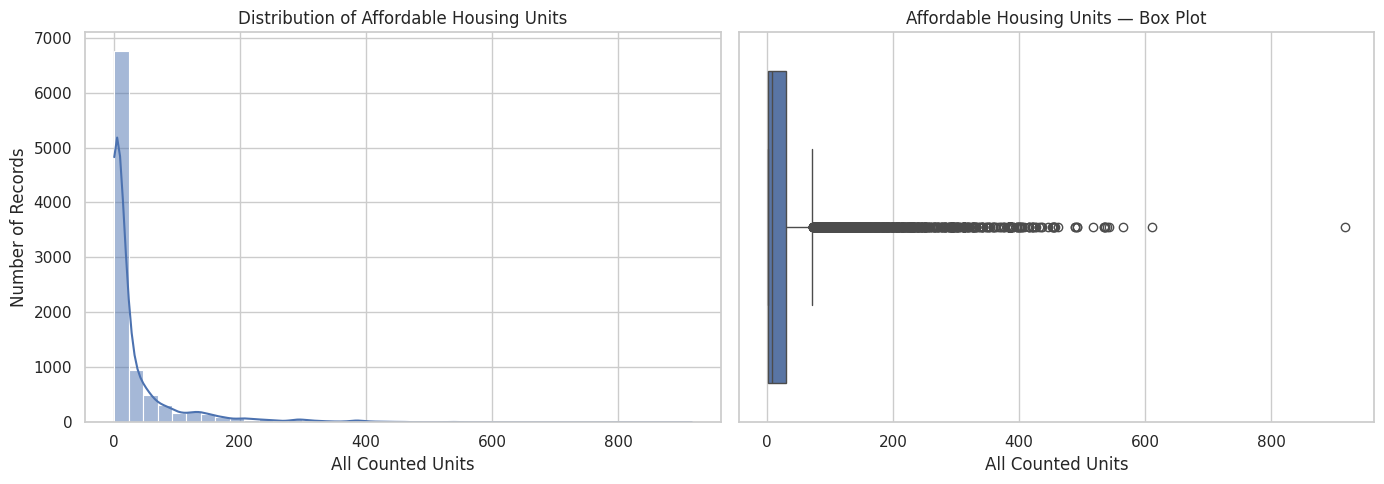

In [17]:
# =====================================================
# 17. HOUSING UNIT DISTRIBUTION
# =====================================================

housing_units = pd.to_numeric(
    df_housing["All Counted Units"],
    errors="coerce"
).dropna()

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Histogram
sns.histplot(
    housing_units,
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    "Distribution of Affordable Housing Units"
)

axes[0].set_xlabel(
    "All Counted Units"
)

axes[0].set_ylabel(
    "Number of Records"
)

# Box plot
sns.boxplot(
    x=housing_units,
    ax=axes[1]
)

axes[1].set_title(
    "Affordable Housing Units — Box Plot"
)

axes[1].set_xlabel(
    "All Counted Units"
)

plt.tight_layout()
plt.show()

### EDA Findings: Distribution of Affordable Housing Units

The distribution of `All Counted Units` is strongly right-skewed.

The mean number of counted affordable housing units is approximately
33.71, while the median is only 8. This indicates that a relatively
small number of large developments increase the overall average.

The interquartile range (IQR) is:

IQR = Q3 - Q1 = 30 - 2 = 28

Using the 1.5 × IQR rule:

- Lower fence = -40
- Upper fence = 72

Records containing more than 72 counted units are therefore
classified as potential statistical outliers.

However, these observations are not automatically considered errors,
as large affordable housing developments may legitimately contain
hundreds of units.

**Cleaning Decision:**

Potential outliers will be investigated rather than automatically
removed. Valid large developments will be retained to preserve
the actual distribution of affordable housing production.

**Analytical Implication:**

Both development counts and affordable housing unit totals should
be considered during the analysis, as they represent different
aspects of housing production.

### 4.3 Affordable Housing Production by Borough

This analysis examines the geographic distribution of affordable
housing production across New York City's five boroughs.

Two metrics are compared:

1. Number of housing project-building records.
2. Total counted affordable housing units.

These metrics provide different perspectives on housing development.
A borough containing more records does not necessarily produce
the largest number of affordable housing units.

The analysis uses the original dataset before cleaning.

HOUSING PRODUCTION BY BOROUGH


,Borough,Housing_Records,Unique_Projects,Affordable_Units
0,Bronx,2630,1686,106661.0
1,Brooklyn,3649,2185,90784.0
2,Manhattan,1485,679,74338.0
3,Queens,1342,1039,42952.0
4,Staten Island,445,351,6211.0


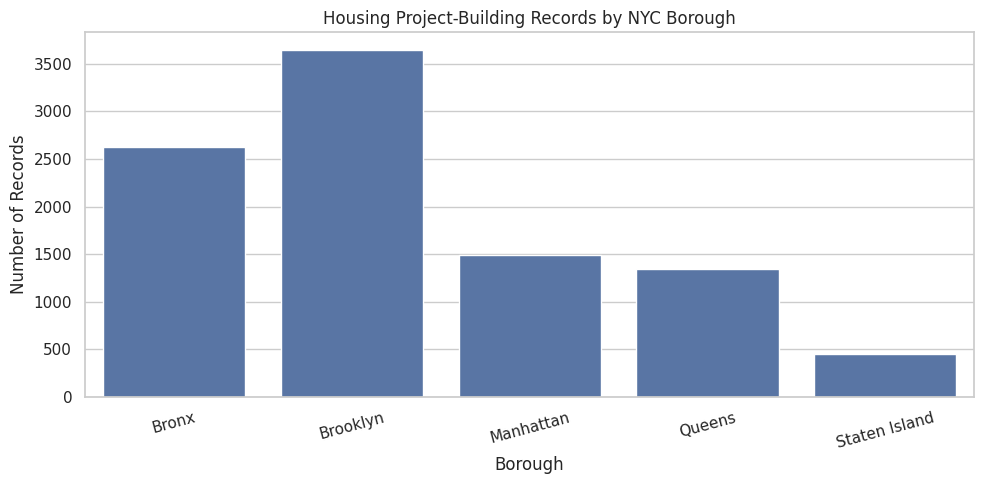

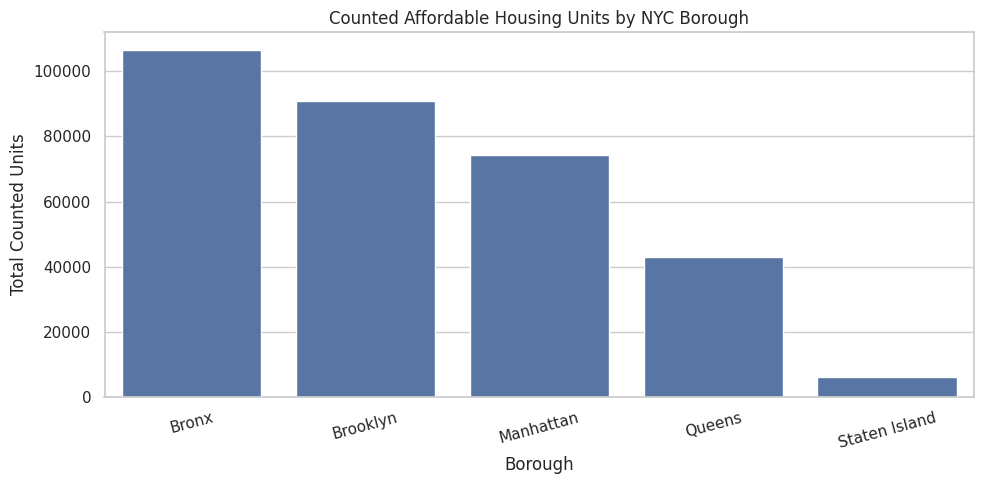

In [18]:
# =====================================================
# 18. AFFORDABLE HOUSING PRODUCTION BY BOROUGH
# =====================================================

# Aggregate housing data by borough
housing_by_borough = (
    df_housing
    .groupby("Borough", dropna=False)
    .agg(
        Housing_Records=("Project ID", "size"),
        Unique_Projects=("Project ID", "nunique"),
        Affordable_Units=("All Counted Units", "sum")
    )
    .reset_index()
)

# Sort by affordable housing units
housing_by_borough = housing_by_borough.sort_values(
    by="Affordable_Units",
    ascending=False
)

print("HOUSING PRODUCTION BY BOROUGH")

display(housing_by_borough)

# Visualization 1: Housing records
plt.figure(figsize=(10, 5))

sns.barplot(
    data=housing_by_borough,
    x="Borough",
    y="Housing_Records"
)

plt.title("Housing Project-Building Records by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# Visualization 2: Affordable housing units
plt.figure(figsize=(10, 5))

sns.barplot(
    data=housing_by_borough,
    x="Borough",
    y="Affordable_Units"
)

plt.title("Counted Affordable Housing Units by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Total Counted Units")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### EDA Findings: Housing Production by Borough

The geographic analysis reveals considerable variation in affordable
housing production across New York City's five boroughs.

**Finding 1: Brooklyn has the most project-building records.**

Brooklyn contains 3,649 housing records and 2,185 unique projects,
making it the borough with the highest recorded development activity
in terms of these measures.

**Finding 2: The Bronx has the largest number of counted affordable units.**

Despite having fewer housing records than Brooklyn, the Bronx accounts
for 106,661 counted affordable housing units, compared with 90,784
in Brooklyn.

This indicates that the number of housing records alone does not
fully represent the scale of affordable housing production.

**Finding 3: Manhattan has relatively high unit production per record.**

Manhattan contains 1,485 housing records but accounts for 74,338
counted affordable units, representing approximately 50 units per
project-building record.

**Finding 4: Staten Island has the lowest recorded production.**

Staten Island has 445 housing records and 6,211 counted affordable
units, the lowest totals among the five boroughs.

**Analytical Implications:**

The results demonstrate the importance of distinguishing between
housing record counts, unique projects, and affordable housing units.

For the subsequent cross-domain analysis, affordable housing unit
totals will be considered alongside development counts.

**Limitations:**

These results describe the complete housing dataset rather than
only the 2022–2025 integration period.

Additionally, the dataset includes both new construction and
preservation projects. Therefore, counted affordable units should
not automatically be interpreted as newly constructed housing units.

### 4.4 Affordable Housing Production Over Time

This section investigates temporal patterns in affordable housing
production using the Project Completion Date.

The analysis examines annual project-building record counts and
counted affordable housing units.

Project Completion Date is initially selected because it identifies
when the overall housing project was completed.

Since a single project may contain multiple buildings, the resulting
annual totals represent building-level records associated with
projects completed during each year.

The original dataset remains unchanged.

The analysis also identifies the overlapping period between housing
and transportation data, which is essential for subsequent integration.

ANNUAL AFFORDABLE HOUSING PRODUCTION


,Completion Year,Housing_Records,Unique_Projects,Affordable_Units
0,2014,367,330,4859.0
1,2015,249,147,7338.0
2,2016,404,222,12578.0
3,2017,684,316,19904.0
4,2018,736,319,27484.0
5,2019,808,432,19870.0
6,2020,481,273,13079.0
7,2021,539,350,15070.0
8,2022,620,517,13498.0
9,2023,741,573,25552.0


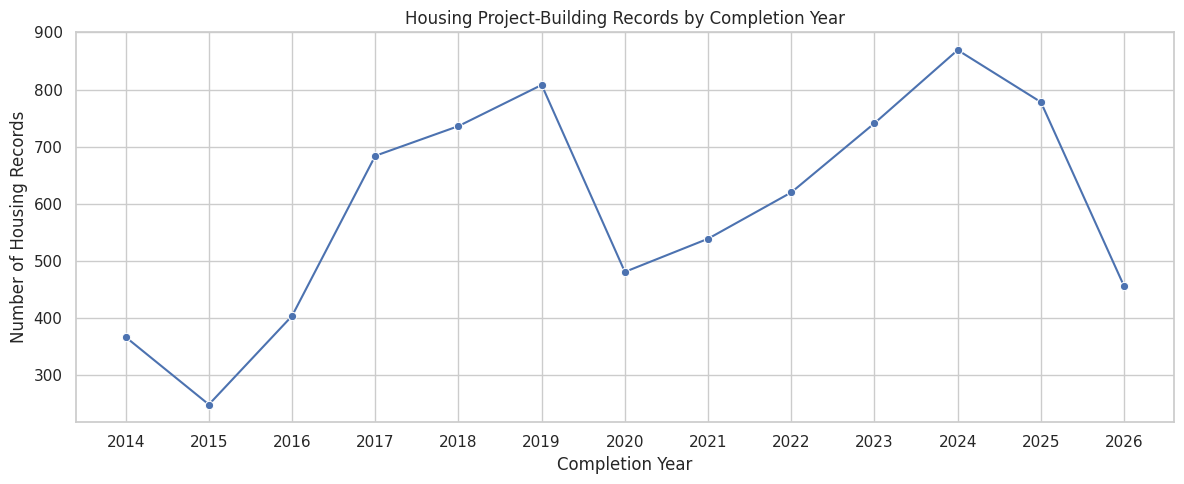

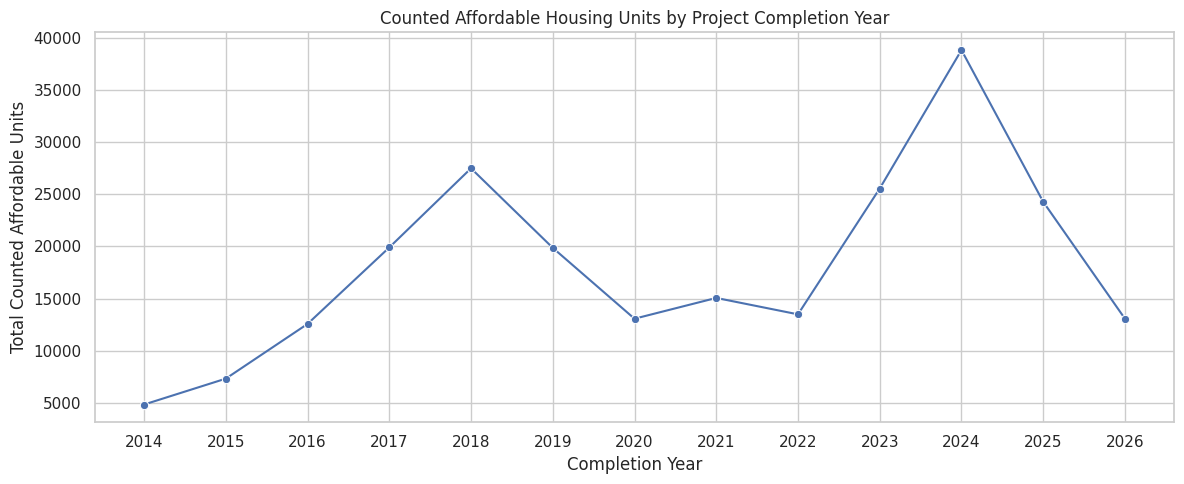

In [19]:
# =====================================================
# 19. HOUSING PRODUCTION OVER TIME
# =====================================================

# Create a temporary copy
housing_temporal = df_housing.copy()

# Convert project completion date
housing_temporal["Project Completion Date"] = pd.to_datetime(
    housing_temporal["Project Completion Date"],
    errors="coerce"
)

# Extract completion year
housing_temporal["Completion Year"] = (
    housing_temporal["Project Completion Date"].dt.year
)

# Keep records with valid completion years
housing_temporal_valid = housing_temporal.dropna(
    subset=["Completion Year"]
).copy()

housing_temporal_valid["Completion Year"] = (
    housing_temporal_valid["Completion Year"].astype(int)
)

# Aggregate by completion year
housing_annual = (
    housing_temporal_valid
    .groupby("Completion Year")
    .agg(
        Housing_Records=("Project ID", "size"),
        Unique_Projects=("Project ID", "nunique"),
        Affordable_Units=("All Counted Units", "sum")
    )
    .reset_index()
    .sort_values("Completion Year")
)

print("ANNUAL AFFORDABLE HOUSING PRODUCTION")

display(housing_annual)

# -----------------------------------------------------
# Visualization 1: Annual Housing Records
# -----------------------------------------------------

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=housing_annual,
    x="Completion Year",
    y="Housing_Records",
    marker="o"
)

plt.title("Housing Project-Building Records by Completion Year")
plt.xlabel("Completion Year")
plt.ylabel("Number of Housing Records")
plt.xticks(housing_annual["Completion Year"])

plt.tight_layout()
plt.show()

# -----------------------------------------------------
# Visualization 2: Annual Affordable Housing Units
# -----------------------------------------------------

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=housing_annual,
    x="Completion Year",
    y="Affordable_Units",
    marker="o"
)

plt.title("Counted Affordable Housing Units by Project Completion Year")
plt.xlabel("Completion Year")
plt.ylabel("Total Counted Affordable Units")
plt.xticks(housing_annual["Completion Year"])

plt.tight_layout()
plt.show()

In [20]:
# =====================================================
# 20. HOUSING PRODUCTION: INTEGRATION PERIOD
# =====================================================

housing_2022_2025 = housing_annual[
    housing_annual["Completion Year"].between(2022, 2025)
].copy()

print("HOUSING PRODUCTION DURING THE INTEGRATION PERIOD")

display(housing_2022_2025)

print("\nTotal Housing Records:",
      housing_2022_2025["Housing_Records"].sum())

print("Total Counted Affordable Units:",
      housing_2022_2025["Affordable_Units"].sum())

HOUSING PRODUCTION DURING THE INTEGRATION PERIOD


,Completion Year,Housing_Records,Unique_Projects,Affordable_Units
8,2022,620,517,13498.0
9,2023,741,573,25552.0
10,2024,869,542,38814.0
11,2025,778,634,24278.0



Total Housing Records: 3008
Total Counted Affordable Units: 102142.0


### EDA Findings: Temporal Patterns in Affordable Housing Production

The temporal analysis examines project-building records and counted
affordable housing units by project completion year.

**Finding 1: Affordable housing production varies considerably by year.**

During the selected integration period (2022–2025), 2024 recorded
the highest number of project-building records (869) and counted
affordable housing units (38,814).

**Finding 2: Housing records and affordable unit totals show different trends.**

In 2025, the dataset recorded 634 unique projects, compared with
542 in 2024. However, the number of counted affordable units
decreased from 38,814 in 2024 to 24,278 in 2025.

This demonstrates that the number of projects does not necessarily
reflect the number of affordable housing units associated with them.

**Finding 3: The selected integration period contains substantial data.**

Between 2022 and 2025, the dataset contains 3,008 project-building
records associated with completed projects and 102,142 counted
affordable housing units.

This provides a useful foundation for investigating relationships
between housing production and transportation safety.

**Limitations:**

- The analysis uses Project Completion Date rather than individual
  Building Completion Date.
- Multiple buildings may belong to the same project.
- The dataset includes both new construction and preservation projects.
- Missing project completion dates exclude some observations.
- The year 2026 is incomplete and is excluded from the primary
  integration period.
- These patterns describe recorded affordable housing activity and
  should not be interpreted as changes in NYC's entire housing stock.

**Integration Decision:**

The years 2022–2025 will be used for the primary geographic-temporal
integration with the transportation dataset.

### 4.5 Housing Production by Construction Type

Affordable housing projects are classified according to their
reporting construction type.

This analysis compares New Construction and Preservation projects
in terms of:

1. Number of project-building records.
2. Number of unique projects.
3. Total counted affordable housing units.
4. Annual affordable housing production.

The objective is to investigate differences between construction
categories and determine how these differences may influence
the subsequent cross-domain analysis.

HOUSING CONSTRUCTION TYPE SUMMARY


,Reporting Construction Type,Housing_Records,Unique_Projects,Affordable_Units
0,New Construction,4766,4278,131448.0
1,Preservation,4785,1652,189498.0


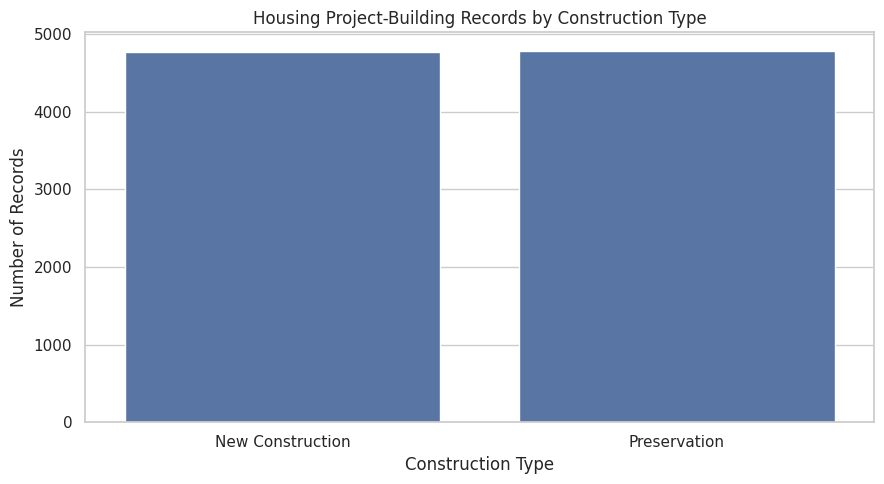

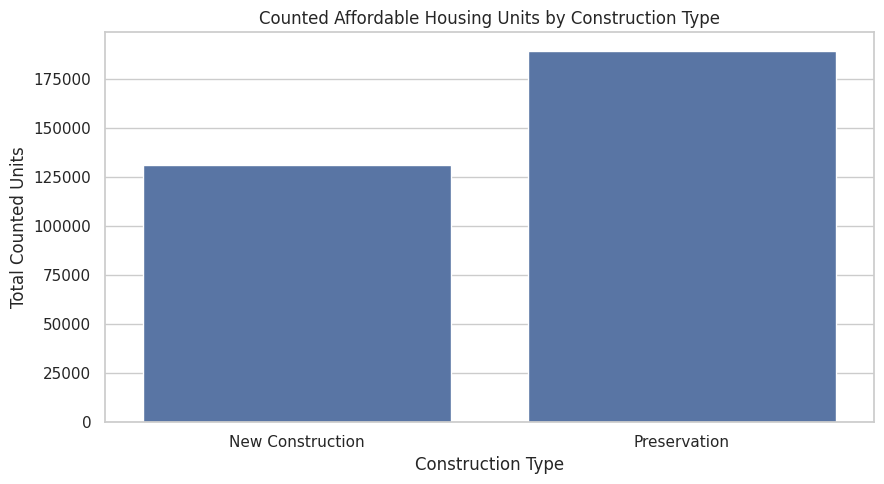

In [21]:
# =====================================================
# 21. HOUSING CONSTRUCTION TYPE ANALYSIS
# =====================================================

# Aggregate by construction type
construction_summary = (
    df_housing
    .groupby("Reporting Construction Type")
    .agg(
        Housing_Records=("Project ID", "size"),
        Unique_Projects=("Project ID", "nunique"),
        Affordable_Units=("All Counted Units", "sum")
    )
    .reset_index()
)

print("HOUSING CONSTRUCTION TYPE SUMMARY")

display(construction_summary)


# -----------------------------------------------------
# Visualization 1: Construction Type Distribution
# -----------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=construction_summary,
    x="Reporting Construction Type",
    y="Housing_Records"
)

plt.title("Housing Project-Building Records by Construction Type")
plt.xlabel("Construction Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()


# -----------------------------------------------------
# Visualization 2: Affordable Units by Construction Type
# -----------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=construction_summary,
    x="Reporting Construction Type",
    y="Affordable_Units"
)

plt.title("Counted Affordable Housing Units by Construction Type")
plt.xlabel("Construction Type")
plt.ylabel("Total Counted Units")

plt.tight_layout()
plt.show()

ANNUAL HOUSING PRODUCTION BY CONSTRUCTION TYPE


,Completion Year,Reporting Construction Type,Housing_Records,Affordable_Units
0,2022,New Construction,409,8674.0
1,2022,Preservation,211,4824.0
2,2023,New Construction,435,13418.0
3,2023,Preservation,306,12134.0
4,2024,New Construction,493,13173.0
5,2024,Preservation,376,25641.0
6,2025,New Construction,527,13540.0
7,2025,Preservation,251,10738.0


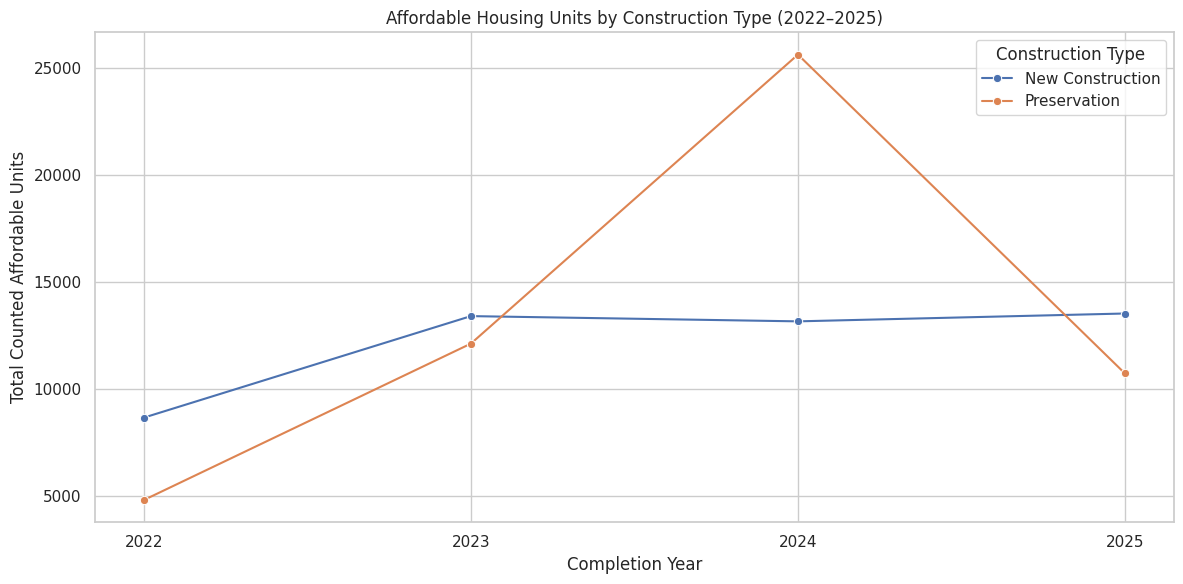

In [22]:
# =====================================================
# 22. CONSTRUCTION TYPE OVER TIME
# =====================================================

# Use the temporal data prepared in Step 21
construction_temporal = housing_temporal_valid.copy()

# Focus on the integration period
construction_temporal = construction_temporal[
    construction_temporal["Completion Year"].between(2022, 2025)
]

# Aggregate by year and construction type
construction_annual = (
    construction_temporal
    .groupby([
        "Completion Year",
        "Reporting Construction Type"
    ])
    .agg(
        Housing_Records=("Project ID", "size"),
        Affordable_Units=("All Counted Units", "sum")
    )
    .reset_index()
)

print("ANNUAL HOUSING PRODUCTION BY CONSTRUCTION TYPE")

display(construction_annual)

# Visualize annual affordable units
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=construction_annual,
    x="Completion Year",
    y="Affordable_Units",
    hue="Reporting Construction Type",
    marker="o"
)

plt.title(
    "Affordable Housing Units by Construction Type (2022–2025)"
)

plt.xlabel("Completion Year")
plt.ylabel("Total Counted Affordable Units")
plt.xticks([2022, 2023, 2024, 2025])
plt.legend(title="Construction Type")

plt.tight_layout()
plt.show()

### EDA Findings: Affordable Housing Construction Types

The analysis reveals important differences between New Construction
and Preservation projects.

**Finding 1: Similar record counts but different project structures.**

New Construction contains 4,766 project-building records across
4,278 unique projects, while Preservation contains 4,785 records
across 1,652 unique projects.

This indicates that Preservation projects tend to involve more
building records per project.

**Finding 2: Preservation accounts for more counted affordable units.**

Preservation accounts for 189,498 counted affordable housing units,
compared with 131,448 units associated with New Construction.

Preservation represents approximately 59% of the total counted
affordable units in the dataset.

**Finding 3: Preservation experienced a substantial increase in 2024.**

During 2024, Preservation accounted for 25,641 counted affordable
units, compared with 13,173 for New Construction.

This explains much of the increase in overall recorded affordable
housing production during 2024.

**Finding 4: New Construction shows greater stability during 2023–2025.**

New Construction recorded approximately 13,000–13,500 counted
affordable units annually during these three years, while
Preservation exhibited greater fluctuations.

**Analytical Implications:**

New Construction and Preservation will be treated as distinct
categories during the cross-domain analysis.

This distinction is important because Preservation generally
concerns existing housing, whereas New Construction concerns
newly developed buildings.

**Limitations:**

- The figures represent recorded affordable housing activity,
  not necessarily net additions to NYC's housing stock.
- The annual analysis uses Project Completion Date.
- Missing unit counts may affect totals.
- Differences in the number of buildings per project influence
  comparisons based on record counts.

## 5 Transportation Dataset — Exploratory Data Analysis

The transportation dataset contains crash records from the
Serious Injury Response, Tracking & Analysis (SIRTA) program.

This analysis investigates the geographic and temporal distribution
of recorded crashes, severe injuries, and fatalities.

The objective is to understand the transportation data before
cleaning and integrating it with the housing dataset.

### 5.1 Transportation Descriptive Statistics

The numerical attributes are examined to identify their
distributions, potential data quality issues, and unusual values.

Particular attention is given to severe injuries, non-severe
injuries, and fatalities.

In [23]:
# =====================================================
# 23. TRANSPORTATION DESCRIPTIVE STATISTICS
# =====================================================

transport_numeric_columns = [
    "Total Non-Severe Injuries",
    "Total Severe Injuries",
    "Total Fatalities",
    "Similar Fatalities & Severe Injuries (3Y Lookback)",
    "Similar Fatalities & All Injuries (3Y Lookback)"
]

transport_statistics = (
    df_transport[transport_numeric_columns]
    .describe()
    .T
)

print("TRANSPORTATION DESCRIPTIVE STATISTICS")

display(transport_statistics)

TRANSPORTATION DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Total Non-Severe Injuries,13310.0,0.270473,0.836031,0.0,0.0,0.0,0.0,19.0
Total Severe Injuries,13310.0,1.011495,0.451514,0.0,1.0,1.0,1.0,7.0
Total Fatalities,13310.0,0.082795,0.294304,0.0,0.0,0.0,0.0,5.0
Similar Fatalities & Severe Injuries (3Y Lookback),11917.0,0.095494,0.421729,0.0,0.0,0.0,0.0,9.0
Similar Fatalities & All Injuries (3Y Lookback),13310.0,1.544328,5.857394,0.0,0.0,0.0,1.0,296.0


### 5.2 Distribution of Crash Injuries and Fatalities

This section examines the distribution of severe injuries,
non-severe injuries, and fatalities among SIRTA crash records.

Histograms are used to understand the frequency distribution
of injury counts.

The analysis helps identify unusual values and provides
a foundation for developing appropriate transportation metrics.

No data is modified during this exploratory analysis.

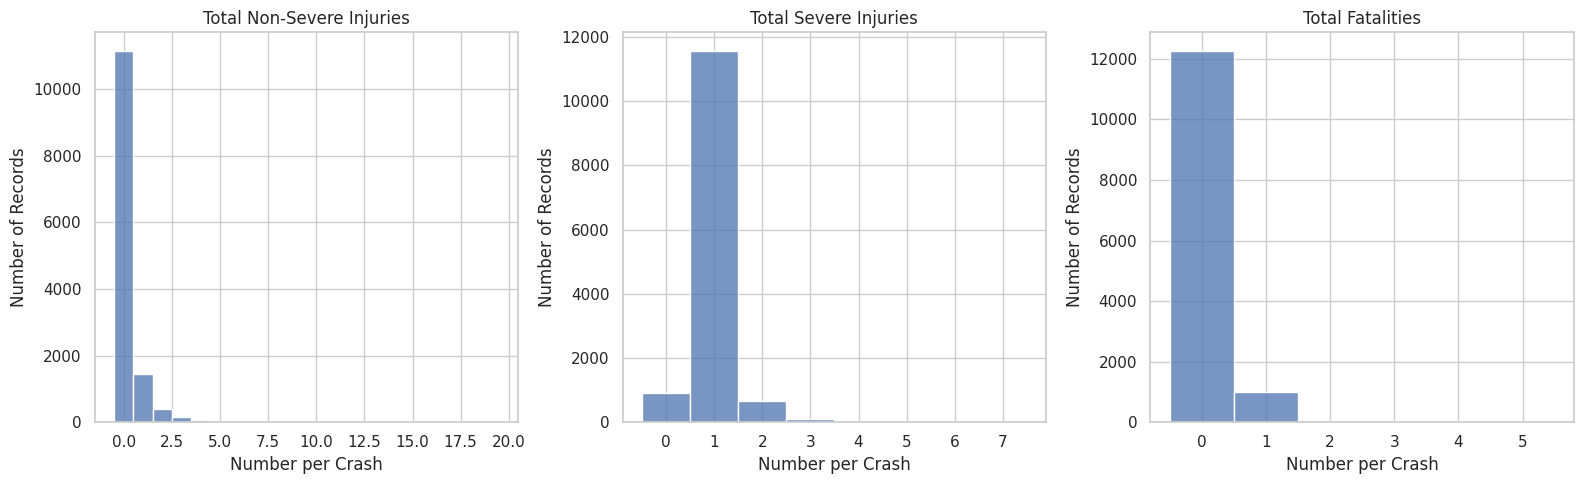

In [24]:
# =====================================================
# 24. INJURY SEVERITY DISTRIBUTION
# =====================================================

injury_columns = [
    "Total Non-Severe Injuries",
    "Total Severe Injuries",
    "Total Fatalities"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for i, column in enumerate(injury_columns):

    sns.histplot(
        data=df_transport,
        x=column,
        discrete=True,
        ax=axes[i]
    )

    axes[i].set_title(column)
    axes[i].set_xlabel("Number per Crash")
    axes[i].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [25]:
# =====================================================
# 25. TRANSPORTATION INJURY TOTALS
# =====================================================

# Exclude records without a valid crash identifier
# for this descriptive summary only.
transport_valid = df_transport[
    df_transport["Collision ID"].notna()
].copy()

injury_summary = pd.DataFrame({
    "Metric": [
        "SIRTA Crash Records",
        "Total Non-Severe Injuries",
        "Total Severe Injuries",
        "Total Fatalities"
    ],
    "Value": [
        len(transport_valid),
        transport_valid["Total Non-Severe Injuries"].sum(),
        transport_valid["Total Severe Injuries"].sum(),
        transport_valid["Total Fatalities"].sum()
    ]
})

print("INITIAL TRANSPORTATION INJURY SUMMARY")

display(injury_summary)

INITIAL TRANSPORTATION INJURY SUMMARY


,Metric,Value
0,SIRTA Crash Records,13310.0
1,Total Non-Severe Injuries,3600.0
2,Total Severe Injuries,13463.0
3,Total Fatalities,1102.0


### EDA Findings: Transportation Injury Severity

The transportation dataset contains 13,310 records with non-missing
Collision ID values before final duplicate resolution.

**Finding 1: Severe injuries are concentrated around one per crash.**

The mean number of severe injuries is approximately 1.01,
and the median is 1.

Most SIRTA records report one severe injury, although some
involve multiple severe injuries.

**Finding 2: Fatalities are relatively uncommon per record.**

The median number of fatalities is zero, indicating that
at least half of the records report no fatalities.

The maximum recorded fatalities in a single observation is five.

**Finding 3: Non-severe injuries are right-skewed.**

Most observations report zero non-severe injuries, while
a smaller number report multiple injuries.

The maximum observed value is 19.

**Finding 4: Historical lookback variables show substantial variation.**

The maximum value of Similar Fatalities & All Injuries
(3Y Lookback) is 296.

These lookback measurements should not be confused with
the injuries caused by the corresponding crash.

**Initial Injury Totals:**

- Non-severe injuries: 3,600
- Severe injuries: 13,463
- Fatalities: 1,102

**Data Quality Considerations:**

The dataset contains 444 records without valid Collision IDs
or core crash information.

Additionally, one non-null Collision ID appears in two
conflicting records.

These issues will be addressed during pre-integration cleaning.

**Analytical Implications:**

The final analysis will distinguish between:

1. Number of recorded crash events.
2. Total severe injuries.
3. Total fatalities.

These metrics represent different aspects of transportation safety.

The findings describe SIRTA records rather than all traffic
incidents occurring in New York City.

### 5.3 Geographic Distribution of SIRTA Crashes

This section examines the geographic distribution of recorded
SIRTA crashes across New York City's five boroughs.

Three metrics are investigated:

1. Number of SIRTA crash records.
2. Total severe injuries.
3. Total fatalities.

The purpose is to identify geographic patterns and understand
how transportation safety measurements vary across boroughs.

The analysis is exploratory and does not establish relationships
with housing production at this stage.

TRANSPORTATION SAFETY BY BOROUGH


,Crash Borough,Crash_Records,Severe_Injuries,Fatalities
1,Brooklyn,3954,3970.0,315.0
3,Queens,3282,3356.0,322.0
2,Manhattan,2733,2718.0,186.0
0,Bronx,2617,2659.0,209.0
4,Staten Island,669,690.0,64.0
5,NaN,55,70.0,6.0


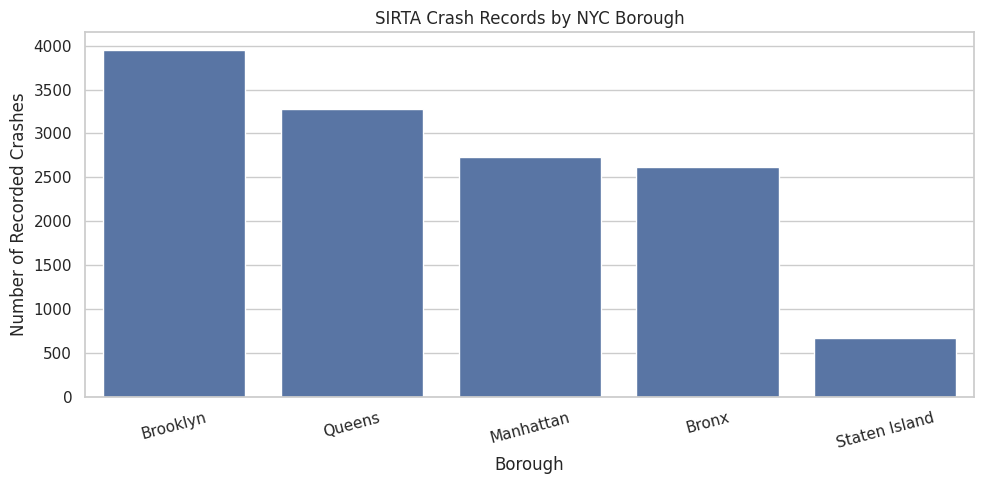

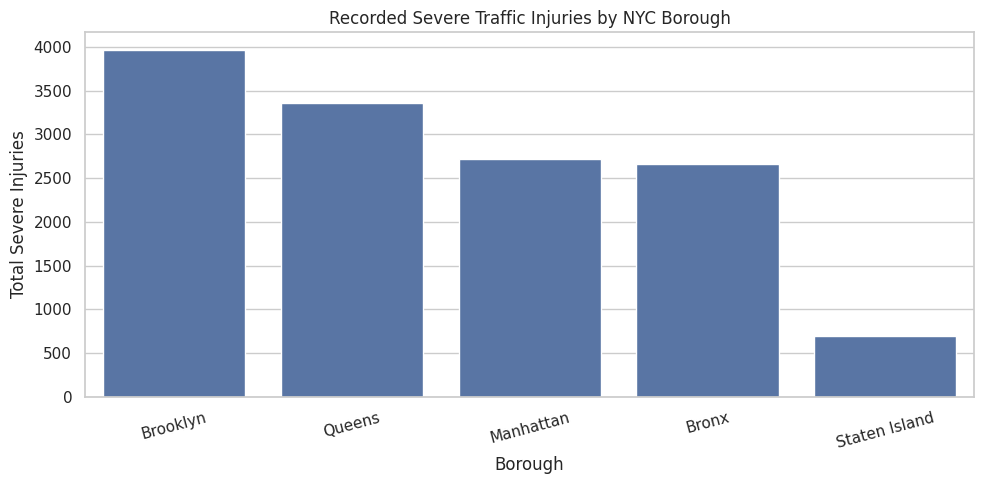

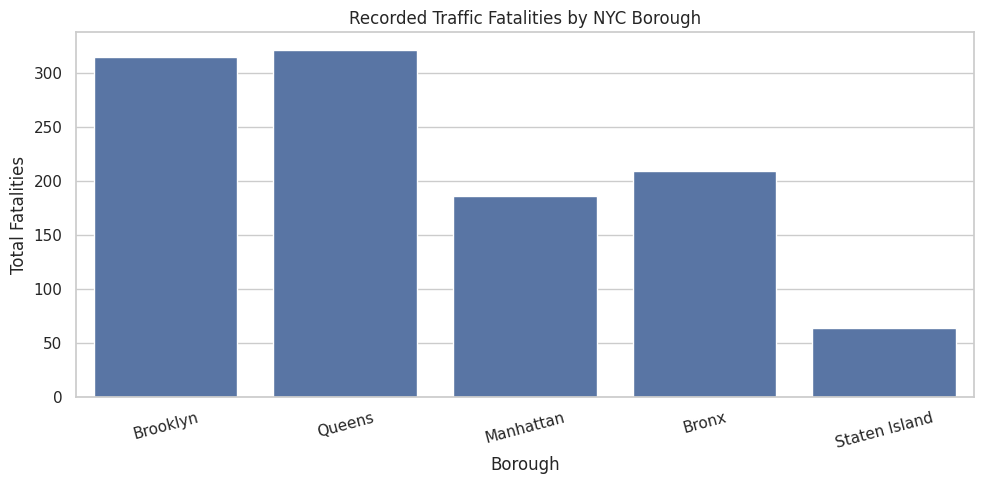

In [26]:
# =====================================================
# 26. TRANSPORTATION GEOGRAPHIC ANALYSIS
# =====================================================

# Temporary subset of records with valid identifiers
transport_geo = df_transport[
    df_transport["Collision ID"].notna()
].copy()

# Aggregate transportation metrics by borough
transport_by_borough = (
    transport_geo
    .groupby("Crash Borough", dropna=False)
    .agg(
        Crash_Records=("Collision ID", "size"),
        Severe_Injuries=("Total Severe Injuries", "sum"),
        Fatalities=("Total Fatalities", "sum")
    )
    .reset_index()
)

# Sort by number of crash records
transport_by_borough = transport_by_borough.sort_values(
    by="Crash_Records",
    ascending=False
)

print("TRANSPORTATION SAFETY BY BOROUGH")

display(transport_by_borough)


# -----------------------------------------------------
# Visualization 1: SIRTA Crash Records by Borough
# -----------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=transport_by_borough,
    x="Crash Borough",
    y="Crash_Records"
)

plt.title("SIRTA Crash Records by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Recorded Crashes")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# -----------------------------------------------------
# Visualization 2: Severe Injuries by Borough
# -----------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=transport_by_borough,
    x="Crash Borough",
    y="Severe_Injuries"
)

plt.title("Recorded Severe Traffic Injuries by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Total Severe Injuries")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# -----------------------------------------------------
# Visualization 3: Fatalities by Borough
# -----------------------------------------------------

plt.figure(figsize=(10, 5))

sns.barplot(
    data=transport_by_borough,
    x="Crash Borough",
    y="Fatalities"
)

plt.title("Recorded Traffic Fatalities by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Total Fatalities")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

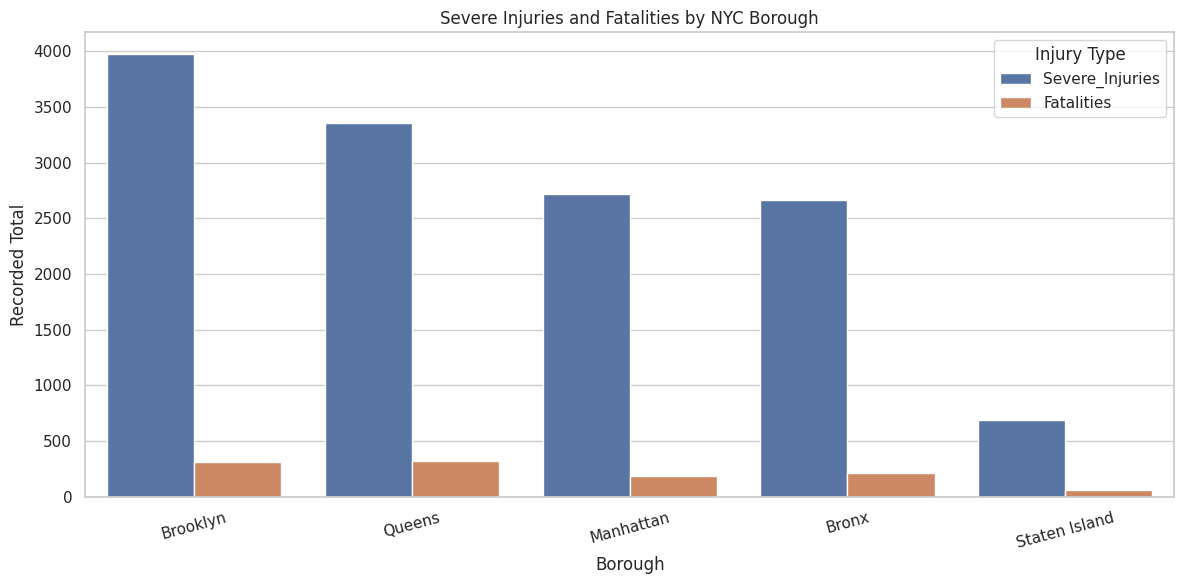

In [27]:
# =====================================================
# 27. SEVERE INJURIES AND FATALITIES BY BOROUGH
# =====================================================

# Exclude missing borough labels for visualization
borough_comparison = transport_by_borough.dropna(
    subset=["Crash Borough"]
).copy()

# Reshape data for grouped bar chart
severity_comparison = borough_comparison.melt(
    id_vars="Crash Borough",
    value_vars=["Severe_Injuries", "Fatalities"],
    var_name="Injury Type",
    value_name="Total"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=severity_comparison,
    x="Crash Borough",
    y="Total",
    hue="Injury Type"
)

plt.title("Severe Injuries and Fatalities by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Recorded Total")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### EDA Findings: Geographic Distribution of SIRTA Crashes

The geographic analysis reveals differences in recorded traffic
injuries and fatalities across New York City's five boroughs.

**Finding 1: Brooklyn has the highest number of SIRTA crash records.**

Brooklyn contains 3,954 recorded crashes and 3,970 severe injuries,
making it the borough with the highest recorded totals for these
two metrics.

**Finding 2: Queens records the highest number of fatalities.**

Queens accounts for 322 fatalities, slightly exceeding Brooklyn's
315 fatalities despite having fewer recorded crashes.

This demonstrates that crash frequency and fatality totals do not
necessarily follow identical geographic patterns.

**Finding 3: Manhattan and the Bronx exhibit different injury patterns.**

Manhattan records 2,733 crashes and 186 fatalities, while the Bronx
records 2,617 crashes and 209 fatalities.

Although Manhattan has more recorded crashes, the Bronx has
more fatalities.

**Finding 4: Staten Island has the lowest recorded totals.**

Staten Island contains 669 crash records, 690 severe injuries,
and 64 fatalities.

**Finding 5: Some crash records lack borough information.**

The dataset contains 55 records with valid Collision IDs but
missing borough values.

These records account for 70 severe injuries and 6 fatalities.

Their geographic information will be investigated during cleaning.

**Analytical Implications:**

The results support examining severe injuries, fatalities, and
recorded crash counts as separate transportation safety metrics.

Geographic comparisons should distinguish between raw totals
and actual risk measures.

**Limitations:**

- The results describe SIRTA records, not all traffic crashes in NYC.
- The analysis uses raw totals rather than population-adjusted rates.
- Records with missing boroughs require further investigation.
- The conflicting Collision ID has not yet been resolved.
- These results cover the available transportation dataset rather
  than only the proposed 2022–2025 integration period.

### 5.4 Temporal Distribution of SIRTA Crashes

This section examines annual patterns in recorded SIRTA crashes,
severe injuries, and fatalities.

The analysis uses Crash Date to identify the year associated with
each recorded event.

The objective is to:

1. Examine annual crash record counts.
2. Investigate trends in severe injuries.
3. Investigate trends in fatalities.
4. Assess the suitability of the proposed 2022–2025 integration period.

The original transportation dataset remains unchanged.

ANNUAL TRANSPORTATION SAFETY SUMMARY


,Crash Year,Crash_Records,Severe_Injuries,Fatalities
0,2022,2879,2863.0,255.0
1,2023,3016,3021.0,247.0
2,2024,3116,3145.0,248.0
3,2025,2947,3029.0,225.0
4,2026,1352,1405.0,127.0


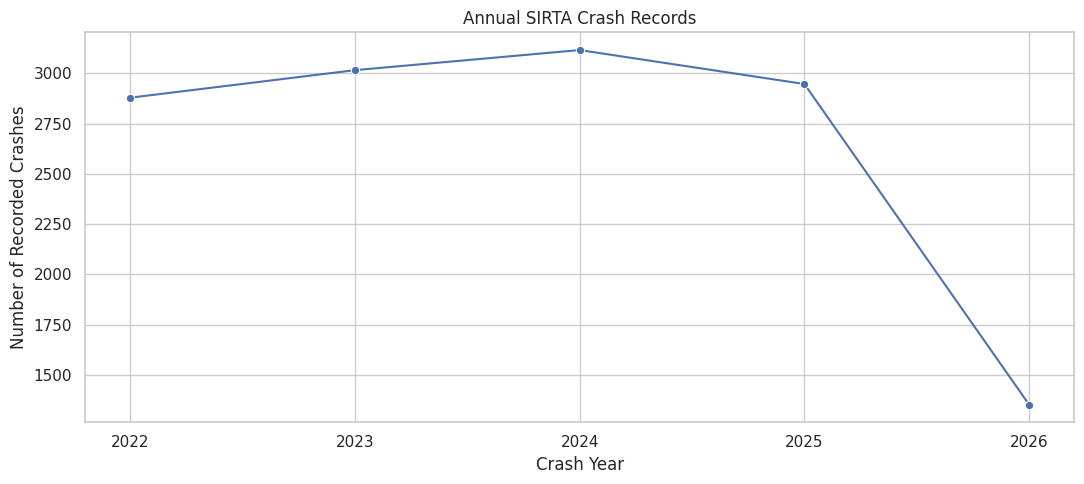

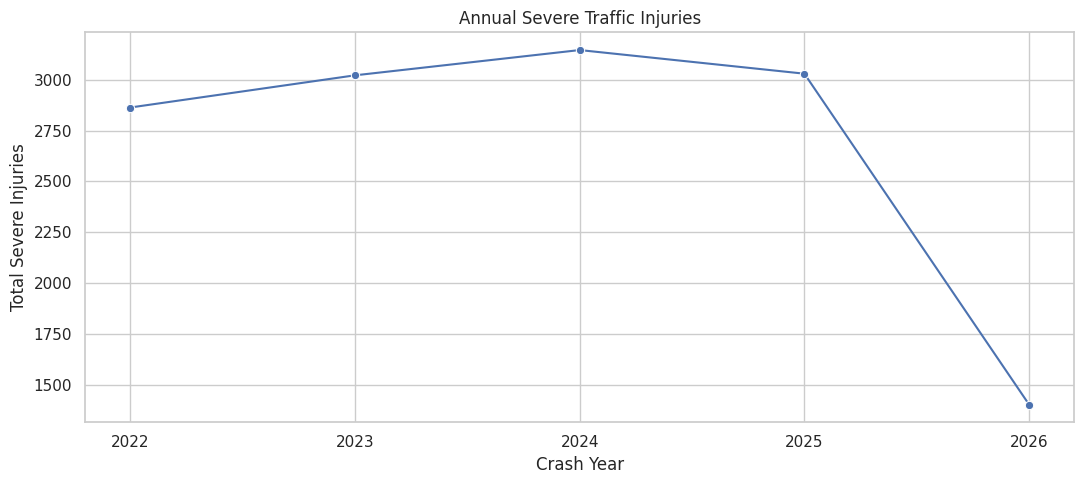

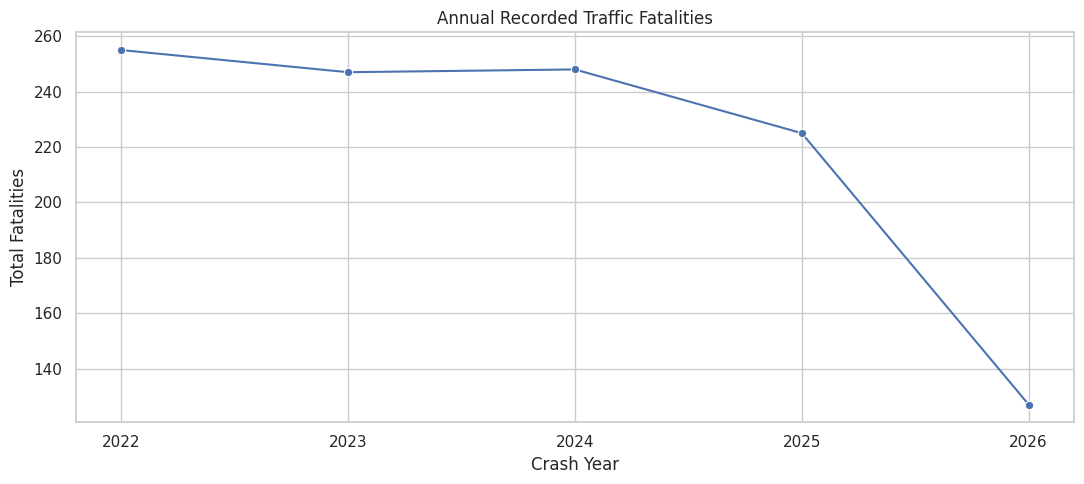

In [28]:
# =====================================================
# 28. TRANSPORTATION TEMPORAL ANALYSIS
# =====================================================

# Create a temporary copy
transport_temporal = df_transport.copy()

# Convert crash dates
transport_temporal["Crash Date"] = pd.to_datetime(
    transport_temporal["Crash Date"],
    errors="coerce"
)

# Extract crash year
transport_temporal["Crash Year"] = (
    transport_temporal["Crash Date"].dt.year
)

# Keep records with valid crash identifiers and dates
transport_temporal_valid = transport_temporal.dropna(
    subset=["Collision ID", "Crash Year"]
).copy()

transport_temporal_valid["Crash Year"] = (
    transport_temporal_valid["Crash Year"].astype(int)
)

# Aggregate transportation metrics by year
transport_annual = (
    transport_temporal_valid
    .groupby("Crash Year")
    .agg(
        Crash_Records=("Collision ID", "size"),
        Severe_Injuries=("Total Severe Injuries", "sum"),
        Fatalities=("Total Fatalities", "sum")
    )
    .reset_index()
    .sort_values("Crash Year")
)

print("ANNUAL TRANSPORTATION SAFETY SUMMARY")

display(transport_annual)


# -----------------------------------------------------
# Visualization 1: Annual SIRTA Crash Records
# -----------------------------------------------------

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=transport_annual,
    x="Crash Year",
    y="Crash_Records",
    marker="o"
)

plt.title("Annual SIRTA Crash Records")
plt.xlabel("Crash Year")
plt.ylabel("Number of Recorded Crashes")
plt.xticks(transport_annual["Crash Year"])

plt.tight_layout()
plt.show()


# -----------------------------------------------------
# Visualization 2: Annual Severe Injuries
# -----------------------------------------------------

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=transport_annual,
    x="Crash Year",
    y="Severe_Injuries",
    marker="o"
)

plt.title("Annual Severe Traffic Injuries")
plt.xlabel("Crash Year")
plt.ylabel("Total Severe Injuries")
plt.xticks(transport_annual["Crash Year"])

plt.tight_layout()
plt.show()


# -----------------------------------------------------
# Visualization 3: Annual Fatalities
# -----------------------------------------------------

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=transport_annual,
    x="Crash Year",
    y="Fatalities",
    marker="o"
)

plt.title("Annual Recorded Traffic Fatalities")
plt.xlabel("Crash Year")
plt.ylabel("Total Fatalities")
plt.xticks(transport_annual["Crash Year"])

plt.tight_layout()
plt.show()

MONTHLY SIRTA RECORD COVERAGE


Crash Month,1,2,3,4,5,6,7,8,9,10,11,12
Crash Year,,,,,,,,,,,,
2022,171,164,206,164,262,277,331,293,267,262,249,233
2023,185,190,204,193,338,259,294,292,295,302,254,210
2024,194,214,219,220,300,288,298,300,287,287,257,252
2025,173,173,245,216,256,272,306,279,310,285,220,212


,Months_With_Records
Crash Year,
2022,12
2023,12
2024,12
2025,12


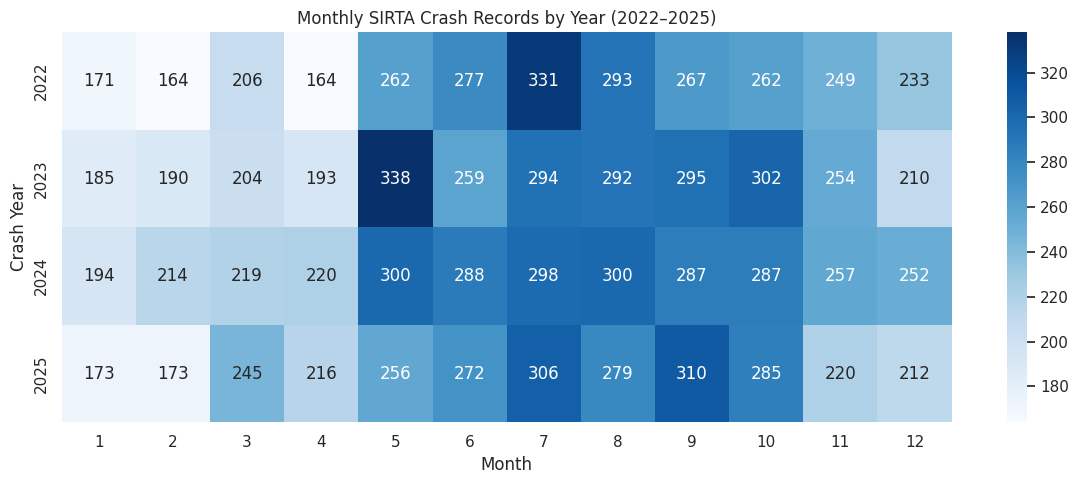

In [29]:
# =====================================================
# 29. MONTHLY TRANSPORTATION COVERAGE
# =====================================================

# Focus on proposed integration years
transport_coverage = transport_temporal_valid[
    transport_temporal_valid["Crash Year"].between(2022, 2025)
].copy()

# Extract month
transport_coverage["Crash Month"] = (
    transport_coverage["Crash Date"].dt.month
)

# Count records by year and month
monthly_coverage = (
    transport_coverage
    .groupby(["Crash Year", "Crash Month"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

print("MONTHLY SIRTA RECORD COVERAGE")

display(monthly_coverage)

# Count months with at least one record
coverage_summary = (
    monthly_coverage.gt(0).sum(axis=1)
    .to_frame("Months_With_Records")
)

display(coverage_summary)

# Visualize monthly coverage
plt.figure(figsize=(12, 5))

sns.heatmap(
    monthly_coverage,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Monthly SIRTA Crash Records by Year (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Crash Year")

plt.tight_layout()
plt.show()

### EDA Findings: Transportation Temporal Patterns

The temporal analysis examines recorded SIRTA crashes, severe
injuries, and fatalities between 2022 and 2026.

**Finding 1: Recorded crashes increased between 2022 and 2024.**

SIRTA crash records increased from 2,879 in 2022 to 3,116
in 2024, representing an increase of approximately 8.2%.

**Finding 2: Severe injuries followed a similar pattern.**

Severe injuries increased from 2,863 in 2022 to 3,145 in 2024,
before decreasing slightly to 3,029 in 2025.

**Finding 3: Fatalities decreased over the primary analysis period.**

Recorded fatalities decreased from 255 in 2022 to 225 in 2025,
representing a reduction of approximately 11.8%.

**Finding 4: All four selected years contain monthly observations.**

The monthly coverage analysis confirms that 2022, 2023, 2024,
and 2025 contain SIRTA records in all 12 months.

This supports their use in the primary geographic-temporal
integration, although it does not guarantee complete reporting.

**Finding 5: Monthly crash counts vary throughout the year.**

Several warmer months exhibit relatively high recorded crash
counts. Further analysis would be required to establish whether
this represents a statistically significant seasonal pattern.

**Limitations:**

- SIRTA does not represent every traffic crash in NYC.
- Annual figures are preliminary because one conflicting
  Collision ID remains unresolved.
- The year 2026 is incomplete and is excluded from full-year
  comparisons.
- Observations in all 12 months do not guarantee complete
  incident reporting.
- These trends do not establish causal relationships.

**Final Temporal Selection:**

The primary analysis will use 2022–2025 because these years
have overlapping housing and transportation observations.

The proposed integration key is ZIP Code + Year.

## 6. Pre-Integration Data Cleaning

### 6.1 Transportation Dataset Cleaning

The transportation dataset contains missing crash identifiers,
a conflicting Collision ID, and incomplete geographic information.

The cleaning process aims to preserve valid observations while
excluding records that cannot reliably represent individual
crash events.

Cleaning decisions:

1. Exclude records without Collision ID values from crash-level analysis.
2. Investigate conflicting Collision IDs.
3. Preserve excluded records separately for auditing.
4. Standardize crash dates.
5. Restrict the main analysis to 2022–2025.
6. Preserve missing geographic values rather than invent locations.

The original dataset is preserved throughout the cleaning process.

In [30]:
# =====================================================
# 30. TRANSPORTATION PRE-INTEGRATION CLEANING
# =====================================================

# Preserve original dataset
transport_clean = df_transport.copy()

original_rows = len(transport_clean)

# -----------------------------------------------------
# 1. Identify records without Collision IDs
# -----------------------------------------------------

missing_id_records = transport_clean[
    transport_clean["Collision ID"].isna()
].copy()

transport_clean = transport_clean.dropna(
    subset=["Collision ID"]
).copy()

print("Records excluded due to missing Collision ID:",
      len(missing_id_records))


# -----------------------------------------------------
# 2. Identify conflicting Collision IDs
# -----------------------------------------------------

conflicting_ids = transport_clean.loc[
    transport_clean["Collision ID"].duplicated(keep=False),
    "Collision ID"
].unique()

conflicting_records = transport_clean[
    transport_clean["Collision ID"].isin(conflicting_ids)
].copy()

print("Conflicting Collision IDs:", conflicting_ids)

# Quarantine conflicting records until verified
transport_clean = transport_clean[
    ~transport_clean["Collision ID"].isin(conflicting_ids)
].copy()

print("Records quarantined due to ID conflicts:",
      len(conflicting_records))


# -----------------------------------------------------
# 3. Remove fully duplicated rows, if any remain
# -----------------------------------------------------

duplicates_before = transport_clean.duplicated().sum()

transport_clean = transport_clean.drop_duplicates()

print("Remaining exact duplicates removed:",
      duplicates_before)


# -----------------------------------------------------
# 4. Standardize crash dates
# -----------------------------------------------------

transport_clean["Crash Date"] = pd.to_datetime(
    transport_clean["Crash Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Identify records with invalid dates
invalid_date_records = transport_clean[
    transport_clean["Crash Date"].isna()
].copy()

transport_clean = transport_clean.dropna(
    subset=["Crash Date"]
).copy()


# -----------------------------------------------------
# 5. Restrict to analysis period: 2022–2025
# -----------------------------------------------------

transport_clean["Year"] = (
    transport_clean["Crash Date"].dt.year
)

transport_clean = transport_clean[
    transport_clean["Year"].between(2022, 2025)
].copy()


# -----------------------------------------------------
# 6. Validate identifier uniqueness
# -----------------------------------------------------

assert transport_clean["Collision ID"].is_unique
assert transport_clean["Collision ID"].notna().all()
assert transport_clean["Crash Date"].notna().all()

print("\n" + "=" * 55)
print("TRANSPORTATION CLEANING SUMMARY")
print("=" * 55)

print("Original records:", original_rows)

print("Missing-ID records:", len(missing_id_records))

print("Conflicting-ID records:", len(conflicting_records))

print("Invalid-date records:", len(invalid_date_records))

print("Remaining records (2022–2025):",
      len(transport_clean))

print("Remaining duplicate Collision IDs:",
      transport_clean["Collision ID"].duplicated().sum())

Records excluded due to missing Collision ID: 444
Conflicting Collision IDs: [4597666.]
Records quarantined due to ID conflicts: 2
Remaining exact duplicates removed: 0

TRANSPORTATION CLEANING SUMMARY
Original records: 13754
Missing-ID records: 444
Conflicting-ID records: 2
Invalid-date records: 0
Remaining records (2022–2025): 11957
Remaining duplicate Collision IDs: 0


In [31]:
# =====================================================
# 31. VALIDATE TRANSPORTATION CLEANING
# =====================================================

validation_summary = pd.DataFrame({
    "Check": [
        "Missing Collision IDs",
        "Duplicate Collision IDs",
        "Missing Crash Dates",
        "Records Outside 2022–2025",
        "Missing ZIP Codes",
        "Missing Boroughs"
    ],

    "Count": [
        transport_clean["Collision ID"].isna().sum(),
        transport_clean["Collision ID"].duplicated().sum(),
        transport_clean["Crash Date"].isna().sum(),
        (~transport_clean["Year"].between(2022, 2025)).sum(),
        transport_clean["ZipCode"].isna().sum(),
        transport_clean["Crash Borough"].isna().sum()
    ]
})

display(validation_summary)

print("\nRecords by year:")

display(
    transport_clean["Year"]
    .value_counts()
    .sort_index()
)

,Check,Count
0,Missing Collision IDs,0
1,Duplicate Collision IDs,0
2,Missing Crash Dates,0
3,Records Outside 2022–2025,0
4,Missing ZIP Codes,4886
5,Missing Boroughs,36



Records by year:


,count
Year,
2022,2879
2023,3015
2024,3116
2025,2947


### 6.2 Transportation Geographic Data Quality

The initial transportation cleaning process retained 11,957
records from the 2022–2025 analysis period.

However, 4,886 records have missing ZIP codes, and 36 records
have missing borough information.

Because ZIP code and year are the proposed integration keys,
geographic completeness is particularly important.

The cleaning process will:

1. Standardize ZIP-code formats.
2. Examine whether missing ZIP codes have valid coordinates.
3. Evaluate the availability of alternative geographic identifiers.
4. Preserve records with incomplete geography for auditing.
5. Avoid assigning geographic identifiers without reliable evidence.

The original dataset will remain unchanged.

In [32]:
# =====================================================
# 32. STANDARDIZE TRANSPORTATION ZIP CODES
# =====================================================

def standardize_zip(series):
    """
    Standardize NYC ZIP codes into five-character strings.

    Missing and invalid values are preserved as missing.
    """

    cleaned = (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
    )

    # Keep only values containing 1–5 digits
    valid_format = cleaned.str.fullmatch(
        r"\d{1,5}",
        na=False
    )

    cleaned = cleaned.where(valid_format)

    # Preserve leading zeros when necessary
    cleaned = cleaned.str.zfill(5)

    return cleaned


transport_clean["ZIP_Code"] = standardize_zip(
    transport_clean["ZipCode"]
)

print("ZIP CODE STANDARDIZATION")

print(
    "Valid ZIP Codes:",
    transport_clean["ZIP_Code"].notna().sum()
)

print(
    "Missing/Invalid ZIP Codes:",
    transport_clean["ZIP_Code"].isna().sum()
)

print("\nSample ZIP Codes:")

display(
    transport_clean[
        ["ZipCode", "ZIP_Code"]
    ].head(10)
)

ZIP CODE STANDARDIZATION
Valid ZIP Codes: 7071
Missing/Invalid ZIP Codes: 4886

Sample ZIP Codes:


,ZipCode,ZIP_Code
0,NaN,<NA>
1,NaN,<NA>
2,NaN,<NA>
3,NaN,<NA>
4,NaN,<NA>
5,NaN,<NA>
6,NaN,<NA>
7,NaN,<NA>
8,NaN,<NA>
9,NaN,<NA>


In [33]:
# =====================================================
# 33. INVESTIGATE MISSING GEOGRAPHIC INFORMATION
# =====================================================

missing_zip_records = transport_clean[
    transport_clean["ZIP_Code"].isna()
].copy()

print("=" * 60)
print("MISSING ZIP CODE INVESTIGATION")
print("=" * 60)

print(
    "Records with missing ZIP:",
    len(missing_zip_records)
)

# Geographic completeness
geo_columns = [
    "Latitude",
    "Longitude",
    "Crash Borough",
    "Community Board",
    "Census Tract (2020)"
]

geo_availability = pd.DataFrame({
    "Geographic Attribute": geo_columns,
    "Available Records": [
        missing_zip_records[col].notna().sum()
        for col in geo_columns
    ]
})

display(geo_availability)

# Check valid coordinates
latitude = pd.to_numeric(
    missing_zip_records["Latitude"],
    errors="coerce"
)

longitude = pd.to_numeric(
    missing_zip_records["Longitude"],
    errors="coerce"
)

valid_coordinates = (
    latitude.between(40.4, 41.0)
    &
    longitude.between(-74.3, -73.6)
)

print(
    "\nMissing-ZIP records with plausible NYC coordinates:",
    valid_coordinates.sum()
)

print(
    "Missing-ZIP records without plausible coordinates:",
    (~valid_coordinates).sum()
)

MISSING ZIP CODE INVESTIGATION
Records with missing ZIP: 4886


,Geographic Attribute,Available Records
0,Latitude,3808
1,Longitude,3808
2,Crash Borough,4850
3,Community Board,703
4,Census Tract (2020),703



Missing-ZIP records with plausible NYC coordinates: 3808
Missing-ZIP records without plausible coordinates: 1078


In [34]:
# =====================================================
# 34. TRANSPORTATION COORDINATE VALIDATION
# =====================================================

transport_lat = pd.to_numeric(
    transport_clean["Latitude"],
    errors="coerce"
)

transport_lon = pd.to_numeric(
    transport_clean["Longitude"],
    errors="coerce"
)

valid_geo = (
    transport_lat.between(40.4, 41.0)
    &
    transport_lon.between(-74.3, -73.6)
)

geo_validation = pd.DataFrame({
    "Metric": [
        "Total Transportation Records",
        "Valid/Plausible Coordinates",
        "Missing or Implausible Coordinates",
        "Valid ZIP Codes",
        "Missing or Invalid ZIP Codes"
    ],

    "Count": [
        len(transport_clean),
        valid_geo.sum(),
        (~valid_geo).sum(),
        transport_clean["ZIP_Code"].notna().sum(),
        transport_clean["ZIP_Code"].isna().sum()
    ]
})

display(geo_validation)

,Metric,Count
0,Total Transportation Records,11957
1,Valid/Plausible Coordinates,9683
2,Missing or Implausible Coordinates,2274
3,Valid ZIP Codes,7071
4,Missing or Invalid ZIP Codes,4886


### 6.3 Geographic Cleaning Strategy

The transportation dataset contains 4,886 records without valid
ZIP codes.

Of these records, 3,808 have plausible geographic coordinates.
However, coordinates alone do not establish a valid ZIP code
without a reliable spatial lookup.

To preserve data integrity, missing ZIP codes are not imputed
using arbitrary values or neighboring observations.

Two analysis subsets are created:

1. A transportation dataset containing all valid crash events.
2. A ZIP-level subset containing records with valid geographic
   identifiers, suitable for integration with the housing dataset.

Records excluded from ZIP-level analysis remain available
for borough-level descriptive analysis.

This approach avoids introducing potentially incorrect
geographic information while preserving the original records.

A limitation is that missing ZIP codes may introduce geographic
selection bias into the integrated analysis.

In [35]:
# =====================================================
# 35. CREATE TRANSPORTATION GEOGRAPHIC SUBSETS
# =====================================================

# Preserve complete cleaned crash-level dataset
transport_all_clean = transport_clean.copy()

# Create subset for ZIP-level integration
transport_zip_clean = transport_all_clean[
    transport_all_clean["ZIP_Code"].notna()
].copy()

# Preserve records excluded from ZIP-level integration
transport_missing_zip = transport_all_clean[
    transport_all_clean["ZIP_Code"].isna()
].copy()

# Validate partition
assert (
    len(transport_zip_clean) + len(transport_missing_zip)
    == len(transport_all_clean)
)

print("=" * 60)
print("TRANSPORTATION GEOGRAPHIC SUBSETS")
print("=" * 60)

print("All valid transportation records:",
      len(transport_all_clean))

print("Records available for ZIP-level integration:",
      len(transport_zip_clean))

print("Records excluded from ZIP-level integration:",
      len(transport_missing_zip))

print("\nZIP-Level Retention Rate:")

print(
    f"{len(transport_zip_clean) / len(transport_all_clean) * 100:.2f}%"
)

print("\nRecords available for ZIP-level integration by year:")

display(
    transport_zip_clean["Year"]
    .value_counts()
    .sort_index()
)

TRANSPORTATION GEOGRAPHIC SUBSETS
All valid transportation records: 11957
Records available for ZIP-level integration: 7071
Records excluded from ZIP-level integration: 4886

ZIP-Level Retention Rate:
59.14%

Records available for ZIP-level integration by year:


,count
Year,
2022,469
2023,2055
2024,2180
2025,2367


### 6.4 Transportation Injury Data Validation

The transportation dataset contains numerical measurements of
severe injuries, non-severe injuries, and fatalities.

These variables must represent valid non-negative integer counts.

The validation process examines:

1. Missing measurements.
2. Negative values.
3. Non-integer observations.
4. Potentially extreme values.
5. Records containing neither severe injuries nor fatalities.

Potential anomalies are investigated rather than automatically
removed.

In [36]:
# =====================================================
# 36. VALIDATE TRANSPORTATION INJURY MEASUREMENTS
# =====================================================

injury_columns = [
    "Total Non-Severe Injuries",
    "Total Severe Injuries",
    "Total Fatalities"
]

validation_results = []

for column in injury_columns:

    values = pd.to_numeric(
        transport_all_clean[column],
        errors="coerce"
    )

    validation_results.append({
        "Column": column,
        "Missing": values.isna().sum(),
        "Negative": (values < 0).sum(),
        "Non_Integer": (
            values.notna() &
            (values % 1 != 0)
        ).sum(),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

injury_validation = pd.DataFrame(validation_results)

print("INJURY VALUE VALIDATION")

display(injury_validation)


# -----------------------------------------------------
# Examine records without severe injuries or fatalities
# -----------------------------------------------------

no_severe_or_fatal = transport_all_clean[
    (transport_all_clean["Total Severe Injuries"] == 0) &
    (transport_all_clean["Total Fatalities"] == 0)
]

print("\nRecords with zero severe injuries AND zero fatalities:",
      len(no_severe_or_fatal))

display(
    no_severe_or_fatal[
        [
            "Collision ID",
            "Crash Date",
            "Total Non-Severe Injuries",
            "Total Severe Injuries",
            "Total Fatalities"
        ]
    ].head(10)
)

INJURY VALUE VALIDATION


,Column,Missing,Negative,Non_Integer,Minimum,Maximum
0,Total Non-Severe Injuries,0,0,0,0.0,19.0
1,Total Severe Injuries,0,0,0,0.0,7.0
2,Total Fatalities,0,0,0,0.0,5.0



Records with zero severe injuries AND zero fatalities: 0


,Collision ID,Crash Date,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities


In [37]:
# =====================================================
# 37. HOUSING ZIP-CODE COMPLETENESS
# =====================================================

housing_zip_test = df_housing.copy()

housing_zip_test["ZIP_Code"] = standardize_zip(
    housing_zip_test["Postcode"]
)

print("=" * 60)
print("HOUSING GEOGRAPHIC COMPLETENESS")
print("=" * 60)

print("Total Housing Records:",
      len(housing_zip_test))

print("Valid ZIP Codes:",
      housing_zip_test["ZIP_Code"].notna().sum())

print("Missing ZIP Codes:",
      housing_zip_test["ZIP_Code"].isna().sum())

print("\nHousing ZIP-Code Retention Rate:")

print(
    f"{housing_zip_test['ZIP_Code'].notna().mean() * 100:.2f}%"
)

print("\nHousing ZIP-Code Distribution by Borough:")

display(
    housing_zip_test
    .groupby("Borough")["ZIP_Code"]
    .agg(
        Total_Records="size",
        Valid_ZIP="count"
    )
)

HOUSING GEOGRAPHIC COMPLETENESS
Total Housing Records: 9551
Valid ZIP Codes: 7593
Missing ZIP Codes: 1958

Housing ZIP-Code Retention Rate:
79.50%

Housing ZIP-Code Distribution by Borough:


,Total_Records,Valid_ZIP
Borough,,
Bronx,2630,2189
Brooklyn,3649,3093
Manhattan,1485,1399
Queens,1342,783
Staten Island,445,129


### 6.5 Housing Pre-Integration Cleaning

The housing dataset contains missing geographic identifiers,
missing project completion dates, and incomplete affordable
housing unit measurements.

The cleaning process standardizes geographic and temporal
attributes while preserving the original observations.

Cleaning decisions:

1. Standardize ZIP codes as five-character strings.
2. Standardize borough names.
3. Convert project and building dates to datetime.
4. Validate affordable housing unit measurements.
5. Preserve missing unit counts rather than assuming zero.
6. Preserve records without completion dates separately.
7. Retain legitimate large developments.

The main integration period is initially 2022–2025.

The original housing dataset remains unchanged.

In [38]:
# =====================================================
# 38. HOUSING PRE-INTEGRATION CLEANING
# =====================================================

# Preserve original data
housing_clean = df_housing.copy()

original_housing_rows = len(housing_clean)

# -----------------------------------------------------
# 1. Standardize ZIP codes
# -----------------------------------------------------

housing_clean["ZIP_Code"] = standardize_zip(
    housing_clean["Postcode"]
)

# -----------------------------------------------------
# 2. Standardize borough names
# -----------------------------------------------------

housing_clean["Borough"] = (
    housing_clean["Borough"]
    .astype("string")
    .str.strip()
    .str.title()
)

# -----------------------------------------------------
# 3. Convert date columns
# -----------------------------------------------------

date_columns = [
    "Project Start Date",
    "Project Completion Date",
    "Building Completion Date"
]

for column in date_columns:
    housing_clean[column] = pd.to_datetime(
        housing_clean[column],
        errors="coerce"
    )

# -----------------------------------------------------
# 4. Create completion year
# -----------------------------------------------------

housing_clean["Year"] = (
    housing_clean["Project Completion Date"].dt.year
)

# -----------------------------------------------------
# 5. Convert housing unit measurements
# -----------------------------------------------------

unit_columns = [
    "All Counted Units",
    "Total Units"
]

for column in unit_columns:
    housing_clean[column] = pd.to_numeric(
        housing_clean[column],
        errors="coerce"
    )

# -----------------------------------------------------
# 6. Standardize construction type
# -----------------------------------------------------

housing_clean["Reporting Construction Type"] = (
    housing_clean["Reporting Construction Type"]
    .astype("string")
    .str.strip()
    .str.title()
)

# -----------------------------------------------------
# 7. Create integration subset
# -----------------------------------------------------

housing_integration = housing_clean[
    housing_clean["Year"].between(2022, 2025)
    &
    housing_clean["ZIP_Code"].notna()
].copy()

# Preserve excluded records for auditing
housing_excluded = housing_clean.loc[
    ~housing_clean.index.isin(housing_integration.index)
].copy()

# -----------------------------------------------------
# 8. Validation
# -----------------------------------------------------

assert len(housing_clean) == original_housing_rows

assert (
    len(housing_integration) + len(housing_excluded)
    == len(housing_clean)
)

assert housing_integration["ZIP_Code"].notna().all()

assert housing_integration["Year"].between(2022, 2025).all()

print("=" * 60)
print("HOUSING CLEANING SUMMARY")
print("=" * 60)

print("Original housing records:", original_housing_rows)

print(
    "Missing project completion dates:",
    housing_clean["Project Completion Date"].isna().sum()
)

print(
    "Missing ZIP codes:",
    housing_clean["ZIP_Code"].isna().sum()
)

print(
    "Missing counted units:",
    housing_clean["All Counted Units"].isna().sum()
)

print(
    "Records available for integration:",
    len(housing_integration)
)

print(
    "Records outside integration subset:",
    len(housing_excluded)
)

print("\nConstruction types:")
display(
    housing_clean["Reporting Construction Type"]
    .value_counts(dropna=False)
)

HOUSING CLEANING SUMMARY
Original housing records: 9551
Missing project completion dates: 1819
Missing ZIP codes: 1958
Missing counted units: 29
Records available for integration: 2293
Records outside integration subset: 7258

Construction types:


,count
Reporting Construction Type,
Preservation,4785
New Construction,4766


In [39]:
# =====================================================
# 39. HOUSING UNIT VALIDATION
# =====================================================

unit_validation = []

for column in ["All Counted Units", "Total Units"]:

    values = housing_clean[column]

    unit_validation.append({
        "Column": column,
        "Missing": values.isna().sum(),
        "Negative": (values < 0).sum(),
        "Non_Integer": (
            values.notna() &
            (values % 1 != 0)
        ).sum(),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

display(pd.DataFrame(unit_validation))


# Check whether counted units exceed total units
invalid_unit_relationship = housing_clean[
    housing_clean["All Counted Units"].notna()
    &
    housing_clean["Total Units"].notna()
    &
    (
        housing_clean["All Counted Units"]
        > housing_clean["Total Units"]
    )
]

print(
    "\nRecords where counted units exceed total units:",
    len(invalid_unit_relationship)
)

display(
    invalid_unit_relationship[
        [
            "Project ID",
            "Building ID",
            "All Counted Units",
            "Total Units"
        ]
    ].head(10)
)

,Column,Missing,Negative,Non_Integer,Minimum,Maximum
0,All Counted Units,29,0,0,1.0,917.0
1,Total Units,7,0,0,1.0,974.0



Records where counted units exceed total units: 0


,Project ID,Building ID,All Counted Units,Total Units


In [40]:
# =====================================================
# 40. HOUSING INTEGRATION COVERAGE BY YEAR
# =====================================================

# Housing records completed during the analysis period
housing_period = housing_clean[
    housing_clean["Year"].between(2022, 2025)
].copy()

coverage_by_year = (
    housing_period
    .groupby("Year")
    .agg(
        Total_Records=("Project ID", "size"),
        Valid_ZIP=("ZIP_Code", "count")
    )
    .reset_index()
)

coverage_by_year["Retention_Percentage"] = (
    coverage_by_year["Valid_ZIP"]
    /
    coverage_by_year["Total_Records"]
    * 100
).round(2)

print("HOUSING ZIP COVERAGE BY YEAR")

display(coverage_by_year)


# -----------------------------------------------------
# Compare with transportation coverage
# -----------------------------------------------------

transport_period = transport_all_clean.copy()

transport_coverage_by_year = (
    transport_period
    .groupby("Year")
    .agg(
        Total_Records=("Collision ID", "size"),
        Valid_ZIP=("ZIP_Code", "count")
    )
    .reset_index()
)

transport_coverage_by_year["Retention_Percentage"] = (
    transport_coverage_by_year["Valid_ZIP"]
    /
    transport_coverage_by_year["Total_Records"]
    * 100
).round(2)

print("\nTRANSPORTATION ZIP COVERAGE BY YEAR")

display(transport_coverage_by_year)

HOUSING ZIP COVERAGE BY YEAR


,Year,Total_Records,Valid_ZIP,Retention_Percentage
0,2022.0,620,435,70.16
1,2023.0,741,574,77.46
2,2024.0,869,706,81.24
3,2025.0,778,578,74.29



TRANSPORTATION ZIP COVERAGE BY YEAR


,Year,Total_Records,Valid_ZIP,Retention_Percentage
0,2022,2879,469,16.29
1,2023,3015,2055,68.16
2,2024,3116,2180,69.96
3,2025,2947,2367,80.32


## 7. Dataset Integration

### 7.1 Integration Strategy

The Housing and Transportation datasets have different observation
levels:

- Housing: Project-building records.
- Transportation: Individual SIRTA crash records.

Directly joining these datasets on ZIP code could produce
many-to-many relationships and artificially duplicate observations.

Therefore, both datasets are aggregated to a common geographic
and temporal level before integration.

**Integration Keys:**
- ZIP Code
- Year

**Analysis Period:** 2022–2025

**Housing Metrics:**
- Number of project-building records.
- Number of unique housing projects.
- Total counted affordable housing units.
- New Construction units.
- Preservation units.

**Transportation Metrics:**
- Number of SIRTA crash records.
- Total severe injuries.
- Total fatalities.
- Total non-severe injuries.

The aggregation process preserves the distinction between
housing construction types and transportation injury severity.

Missing numeric measurements are not automatically treated
as genuine zeros.

The integration is intended to reveal geographic-temporal
associations rather than establish causal relationships.

In [41]:
# =====================================================
# 41. AGGREGATE HOUSING DATA BY ZIP CODE AND YEAR
# =====================================================

# Start from the cleaned housing integration subset
housing_agg_source = housing_integration.copy()

# Create construction-specific unit measures
housing_agg_source["New_Construction_Units"] = (
    housing_agg_source["All Counted Units"].where(
        housing_agg_source["Reporting Construction Type"]
        == "New Construction",
        0
    )
)

housing_agg_source["Preservation_Units"] = (
    housing_agg_source["All Counted Units"].where(
        housing_agg_source["Reporting Construction Type"]
        == "Preservation",
        0
    )
)

# Preserve missing unit values in aggregation
def sum_preserving_missing(series):
    return series.sum(min_count=1)

# Aggregate at the ZIP-year level
housing_aggregated = (
    housing_agg_source
    .groupby(["ZIP_Code", "Year"])
    .agg(
        Housing_Records=("Project ID", "size"),

        Unique_Housing_Projects=(
            "Project ID", "nunique"
        ),

        Affordable_Units=(
            "All Counted Units", sum_preserving_missing
        ),

        New_Construction_Units=(
            "New_Construction_Units", sum_preserving_missing
        ),

        Preservation_Units=(
            "Preservation_Units", sum_preserving_missing
        ),

        Missing_Unit_Records=(
            "All Counted Units",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# Validate aggregation
assert not housing_aggregated.duplicated(
    ["ZIP_Code", "Year"]
).any()

assert (
    housing_aggregated["Housing_Records"].sum()
    == len(housing_integration)
)

print("=" * 60)
print("HOUSING AGGREGATION SUMMARY")
print("=" * 60)

print("Original integration records:", len(housing_integration))

print("Aggregated ZIP-Year combinations:", len(housing_aggregated))

print("\nAggregated Housing Data:")
display(housing_aggregated.head(10))

HOUSING AGGREGATION SUMMARY
Original integration records: 2293
Aggregated ZIP-Year combinations: 377

Aggregated Housing Data:


,ZIP_Code,Year,Housing_Records,Unique_Housing_Projects,Affordable_Units,New_Construction_Units,Preservation_Units,Missing_Unit_Records
0,10001,2023.0,2,2,378.0,378.0,0.0,0
1,10001,2024.0,1,1,35.0,35.0,0.0,0
2,10001,2025.0,1,1,70.0,70.0,0.0,0
3,10002,2022.0,2,2,135.0,135.0,0.0,0
4,10002,2023.0,1,1,18.0,18.0,0.0,0
5,10002,2024.0,3,3,335.0,335.0,0.0,0
6,10002,2025.0,1,1,172.0,0.0,172.0,0
7,10003,2022.0,1,1,151.0,0.0,151.0,0
8,10003,2024.0,1,1,64.0,0.0,64.0,0
9,10003,2025.0,1,1,42.0,0.0,42.0,0


In [42]:
# =====================================================
# 42. AGGREGATE TRANSPORTATION DATA BY ZIP AND YEAR
# =====================================================

# Use transportation records with valid ZIP codes
transport_agg_source = transport_zip_clean.copy()

# Aggregate at ZIP-year level
transport_aggregated = (
    transport_agg_source
    .groupby(["ZIP_Code", "Year"])
    .agg(
        Crash_Records=("Collision ID", "size"),

        Severe_Injuries=(
            "Total Severe Injuries", "sum"
        ),

        Fatalities=(
            "Total Fatalities", "sum"
        ),

        Non_Severe_Injuries=(
            "Total Non-Severe Injuries", "sum"
        )
    )
    .reset_index()
)

# Validate aggregation
assert not transport_aggregated.duplicated(
    ["ZIP_Code", "Year"]
).any()

assert (
    transport_aggregated["Crash_Records"].sum()
    == len(transport_zip_clean)
)

print("=" * 60)
print("TRANSPORTATION AGGREGATION SUMMARY")
print("=" * 60)

print(
    "Original transportation integration records:",
    len(transport_zip_clean)
)

print(
    "Aggregated ZIP-Year combinations:",
    len(transport_aggregated)
)

print("\nAggregated Transportation Data:")
display(transport_aggregated.head(10))

TRANSPORTATION AGGREGATION SUMMARY
Original transportation integration records: 7071
Aggregated ZIP-Year combinations: 668

Aggregated Transportation Data:


,ZIP_Code,Year,Crash_Records,Severe_Injuries,Fatalities,Non_Severe_Injuries
0,10000,2022,1,1.0,0.0,0.0
1,10000,2023,3,3.0,0.0,0.0
2,10000,2024,1,1.0,0.0,4.0
3,10000,2025,31,31.0,1.0,7.0
4,10001,2022,7,7.0,0.0,0.0
5,10001,2023,24,22.0,2.0,9.0
6,10001,2024,16,19.0,0.0,18.0
7,10001,2025,18,17.0,1.0,3.0
8,10002,2022,4,4.0,0.0,0.0
9,10002,2023,25,24.0,2.0,6.0


### 7.2 Integration Implementation

After independently aggregating housing and transportation
observations, the datasets are merged using ZIP Code and Year.

An outer join is initially used to investigate matching coverage
and preserve unmatched geographic-temporal combinations.

The merge indicator distinguishes:

- Matched ZIP-year combinations.
- Housing-only combinations.
- Transportation-only combinations.

The resulting dataset will undergo post-integration cleaning
and validation before being used for research visualizations.

Unmatched observations are not automatically interpreted as
zero housing production or zero traffic incidents.

In [43]:
# =====================================================
# 43. MERGE HOUSING AND TRANSPORTATION DATASETS
# =====================================================

# Standardize year types before merging
housing_aggregated["Year"] = (
    housing_aggregated["Year"].astype(int)
)

transport_aggregated["Year"] = (
    transport_aggregated["Year"].astype(int)
)

# Perform outer join
integrated_raw = pd.merge(
    housing_aggregated,
    transport_aggregated,
    on=["ZIP_Code", "Year"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

print("=" * 60)
print("DATASET INTEGRATION SUMMARY")
print("=" * 60)

print("Housing ZIP-Year combinations:", len(housing_aggregated))

print("Transportation ZIP-Year combinations:", len(transport_aggregated))

print("Total integrated combinations:", len(integrated_raw))

print("\nMerge Results:")
display(integrated_raw["_merge"].value_counts())

print("\nIntegrated Dataset Preview:")
display(integrated_raw.head(10))

print("\nIntegrated Dataset Shape:")
print(integrated_raw.shape)

DATASET INTEGRATION SUMMARY
Housing ZIP-Year combinations: 377
Transportation ZIP-Year combinations: 668
Total integrated combinations: 678

Merge Results:


,count
_merge,
both,367
right_only,301
left_only,10



Integrated Dataset Preview:


,ZIP_Code,Year,Housing_Records,Unique_Housing_Projects,Affordable_Units,New_Construction_Units,Preservation_Units,Missing_Unit_Records,Crash_Records,Severe_Injuries,Fatalities,Non_Severe_Injuries,_merge
0,10000,2022,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,0.0,right_only
1,10000,2023,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,0.0,0.0,right_only
2,10000,2024,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,0.0,4.0,right_only
3,10000,2025,NaN,NaN,NaN,NaN,NaN,NaN,31.0,31.0,1.0,7.0,right_only
4,10001,2022,NaN,NaN,NaN,NaN,NaN,NaN,7.0,7.0,0.0,0.0,right_only
5,10001,2023,2.0,2.0,378.0,378.0,0.0,0.0,24.0,22.0,2.0,9.0,both
6,10001,2024,1.0,1.0,35.0,35.0,0.0,0.0,16.0,19.0,0.0,18.0,both
7,10001,2025,1.0,1.0,70.0,70.0,0.0,0.0,18.0,17.0,1.0,3.0,both
8,10002,2022,2.0,2.0,135.0,135.0,0.0,0.0,4.0,4.0,0.0,0.0,both
9,10002,2023,1.0,1.0,18.0,18.0,0.0,0.0,25.0,24.0,2.0,6.0,both



Integrated Dataset Shape:
(678, 13)


## 8. Post-Integration Data Cleaning

### 8.1 Post-Integration Quality Assessment

The housing and transportation datasets were successfully integrated
using ZIP Code and Year.

The initial outer join produced:

- 367 matched ZIP-year combinations.
- 10 housing-only combinations.
- 301 transportation-only combinations.

The integrated dataset requires additional validation because
unmatched observations introduce missing values.

These missing values must not automatically be interpreted as zero.

This stage investigates missingness, validates integration keys,
and prepares a reliable dataset for cross-domain analysis.

In [44]:
# =====================================================
# 44. POST-INTEGRATION MISSING VALUE ANALYSIS
# =====================================================

integrated_clean = integrated_raw.copy()

# Calculate missing values
post_missing = pd.DataFrame({
    "Column": integrated_clean.columns,
    "Missing_Count": integrated_clean.isna().sum().values,
    "Missing_Percentage": (
        integrated_clean.isna().mean().values * 100
    ).round(2)
})

post_missing = post_missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

print("POST-INTEGRATION MISSING VALUES")

display(post_missing)

print("\nMERGE CATEGORY DISTRIBUTION")

display(
    integrated_clean["_merge"].value_counts()
)

print("\nMISSING VALUES IN MATCHED RECORDS")

matched_data = integrated_clean[
    integrated_clean["_merge"] == "both"
]

display(
    matched_data.isna().sum().to_frame("Missing_Count")
)

POST-INTEGRATION MISSING VALUES


,Column,Missing_Count,Missing_Percentage
2,Housing_Records,301,44.40
4,Affordable_Units,301,44.40
3,Unique_Housing_Projects,301,44.40
6,Preservation_Units,301,44.40
5,New_Construction_Units,301,44.40
7,Missing_Unit_Records,301,44.40
10,Fatalities,10,1.47
9,Severe_Injuries,10,1.47
8,Crash_Records,10,1.47
11,Non_Severe_Injuries,10,1.47



MERGE CATEGORY DISTRIBUTION


,count
_merge,
both,367
right_only,301
left_only,10



MISSING VALUES IN MATCHED RECORDS


,Missing_Count
ZIP_Code,0
Year,0
Housing_Records,0
Unique_Housing_Projects,0
Affordable_Units,0
New_Construction_Units,0
Preservation_Units,0
Missing_Unit_Records,0
Crash_Records,0
Severe_Injuries,0


### 8.2 Matched Cross-Domain Dataset

The integrated dataset includes matched and unmatched ZIP-year
combinations.

For analyses requiring measurements from both domains, a matched
subset is created.

Unmatched observations are preserved separately for auditing and
possible supplementary analysis.

This prevents missing values introduced by the outer join from
being incorrectly interpreted as observed zeros.

The matched dataset contains one observation per ZIP code and year.

In [45]:
# =====================================================
# 45. CREATE MATCHED CROSS-DOMAIN DATASET
# =====================================================

# Preserve unmatched combinations
unmatched_data = integrated_clean[
    integrated_clean["_merge"] != "both"
].copy()

# Retain matched combinations
integrated_matched = integrated_clean[
    integrated_clean["_merge"] == "both"
].copy()

# Convert year to integer
integrated_matched["Year"] = (
    integrated_matched["Year"].astype(int)
)

# Preserve ZIP code as text
integrated_matched["ZIP_Code"] = (
    integrated_matched["ZIP_Code"].astype("string")
)

# Remove redundant merge indicator
integrated_matched = integrated_matched.drop(
    columns=["_merge"]
)

# Validate keys
assert not integrated_matched.duplicated(
    ["ZIP_Code", "Year"]
).any()

assert integrated_matched["ZIP_Code"].notna().all()

assert integrated_matched["Year"].between(2022, 2025).all()

print("=" * 60)
print("MATCHED DATASET SUMMARY")
print("=" * 60)

print("Matched records:", len(integrated_matched))

print("Unmatched records:", len(unmatched_data))

print("Columns:", integrated_matched.shape[1])

print("\nMatched dataset preview:")

display(integrated_matched.head(10))

MATCHED DATASET SUMMARY
Matched records: 367
Unmatched records: 311
Columns: 12

Matched dataset preview:


,ZIP_Code,Year,Housing_Records,Unique_Housing_Projects,Affordable_Units,New_Construction_Units,Preservation_Units,Missing_Unit_Records,Crash_Records,Severe_Injuries,Fatalities,Non_Severe_Injuries
5,10001,2023,2.0,2.0,378.0,378.0,0.0,0.0,24.0,22.0,2.0,9.0
6,10001,2024,1.0,1.0,35.0,35.0,0.0,0.0,16.0,19.0,0.0,18.0
7,10001,2025,1.0,1.0,70.0,70.0,0.0,0.0,18.0,17.0,1.0,3.0
8,10002,2022,2.0,2.0,135.0,135.0,0.0,0.0,4.0,4.0,0.0,0.0
9,10002,2023,1.0,1.0,18.0,18.0,0.0,0.0,25.0,24.0,2.0,6.0
10,10002,2024,3.0,3.0,335.0,335.0,0.0,0.0,26.0,25.0,5.0,10.0
11,10002,2025,1.0,1.0,172.0,0.0,172.0,0.0,17.0,16.0,1.0,2.0
12,10003,2022,1.0,1.0,151.0,0.0,151.0,0.0,2.0,1.0,1.0,0.0
14,10003,2024,1.0,1.0,64.0,0.0,64.0,0.0,15.0,15.0,0.0,0.0
15,10003,2025,1.0,1.0,42.0,0.0,42.0,0.0,22.0,21.0,2.0,2.0


### 8.3 Integrated Data Validation

After creating the matched dataset, numerical measurements
are validated.

The validation examines:

1. Missing values in important research metrics.
2. Negative values in count measurements.
3. Duplicate geographic-temporal keys.
4. Consistency between construction categories and total
   counted affordable housing units.
5. Consistency between crash records and severe injury totals.

The purpose is to ensure that the integrated dataset preserves
the meaning of the original source measurements.

In [46]:
# =====================================================
# 46. VALIDATE INTEGRATED MEASUREMENTS
# =====================================================

metric_columns = [
    "Housing_Records",
    "Unique_Housing_Projects",
    "Affordable_Units",
    "New_Construction_Units",
    "Preservation_Units",
    "Missing_Unit_Records",
    "Crash_Records",
    "Severe_Injuries",
    "Fatalities",
    "Non_Severe_Injuries"
]

validation_results = []

for column in metric_columns:

    values = pd.to_numeric(
        integrated_matched[column],
        errors="coerce"
    )

    validation_results.append({
        "Metric": column,
        "Missing": values.isna().sum(),
        "Negative": (values < 0).sum(),
        "Non_Integer": (
            values.notna() &
            (values % 1 != 0)
        ).sum(),
        "Minimum": values.min(),
        "Maximum": values.max()
    })

validation_table = pd.DataFrame(validation_results)

print("INTEGRATED METRIC VALIDATION")

display(validation_table)


# -----------------------------------------------------
# Check housing category consistency
# -----------------------------------------------------

housing_consistency = (
    integrated_matched["New_Construction_Units"]
    +
    integrated_matched["Preservation_Units"]
)

mismatch_mask = (
    integrated_matched["Affordable_Units"].notna()
    &
    housing_consistency.notna()
    &
    (
        housing_consistency
        != integrated_matched["Affordable_Units"]
    )
)

print("\nHousing category total mismatches:",
      mismatch_mask.sum())

display(
    integrated_matched.loc[
        mismatch_mask,
        [
            "ZIP_Code",
            "Year",
            "Affordable_Units",
            "New_Construction_Units",
            "Preservation_Units"
        ]
    ]
)

print("\nDuplicate ZIP-Year keys:",
      integrated_matched.duplicated(
          ["ZIP_Code", "Year"]
      ).sum())

INTEGRATED METRIC VALIDATION


,Metric,Missing,Negative,Non_Integer,Minimum,Maximum
0,Housing_Records,0,0,0,1.0,79.0
1,Unique_Housing_Projects,0,0,0,1.0,25.0
2,Affordable_Units,0,0,0,1.0,15372.0
3,New_Construction_Units,0,0,0,0.0,1338.0
4,Preservation_Units,0,0,0,0.0,15372.0
5,Missing_Unit_Records,0,0,0,0.0,4.0
6,Crash_Records,0,0,0,1.0,43.0
7,Severe_Injuries,0,0,0,0.0,43.0
8,Fatalities,0,0,0,0.0,5.0
9,Non_Severe_Injuries,0,0,0,0.0,35.0



Housing category total mismatches: 0


,ZIP_Code,Year,Affordable_Units,New_Construction_Units,Preservation_Units



Duplicate ZIP-Year keys: 0


In [47]:
# =====================================================
# 47. VERIFY AGGREGATION INTEGRITY
# =====================================================

print("=" * 60)
print("AGGREGATION INTEGRITY CHECK")
print("=" * 60)

# Housing counts
original_housing_count = len(housing_integration)

aggregated_housing_count = (
    housing_aggregated["Housing_Records"].sum()
)

print("\nHousing Record Preservation")

print("Source records:", original_housing_count)
print("Aggregated records:", aggregated_housing_count)

assert original_housing_count == aggregated_housing_count


# Transportation counts
original_transport_count = len(transport_zip_clean)

aggregated_transport_count = (
    transport_aggregated["Crash_Records"].sum()
)

print("\nTransportation Record Preservation")

print("Source records:", original_transport_count)
print("Aggregated records:", aggregated_transport_count)

assert original_transport_count == aggregated_transport_count


# Housing unit totals
source_housing_units = (
    housing_integration["All Counted Units"].sum()
)

aggregated_housing_units = (
    housing_aggregated["Affordable_Units"].sum()
)

print("\nHousing Unit Preservation")

print("Source counted units:", source_housing_units)
print("Aggregated counted units:", aggregated_housing_units)

assert np.isclose(
    source_housing_units,
    aggregated_housing_units
)


# Severe injury totals
source_severe_injuries = (
    transport_zip_clean["Total Severe Injuries"].sum()
)

aggregated_severe_injuries = (
    transport_aggregated["Severe_Injuries"].sum()
)

print("\nSevere Injury Preservation")

print("Source severe injuries:", source_severe_injuries)
print("Aggregated severe injuries:", aggregated_severe_injuries)

assert np.isclose(
    source_severe_injuries,
    aggregated_severe_injuries
)

print("\nAll aggregation integrity checks passed!")

AGGREGATION INTEGRITY CHECK

Housing Record Preservation
Source records: 2293
Aggregated records: 2293

Transportation Record Preservation
Source records: 7071
Aggregated records: 7071

Housing Unit Preservation
Source counted units: 101025.0
Aggregated counted units: 101025.0

Severe Injury Preservation
Source severe injuries: 7166.0
Aggregated severe injuries: 7166.0

All aggregation integrity checks passed!


### 8.4 Housing Measurement Completeness

Although the matched dataset contains no missing aggregate values,
some original housing records have missing counted-unit measurements.

Aggregating non-missing values does not guarantee that the resulting
total is complete.

Therefore, each ZIP-year combination is assigned a completeness flag.

The flag distinguishes between:

- Complete housing-unit totals.
- Housing-unit totals based on partially missing source measurements.

This allows subsequent research analyses to exclude incomplete
measurements when necessary without discarding useful records.

In [48]:
# =====================================================
# 48. FLAG INCOMPLETE HOUSING MEASUREMENTS
# =====================================================

final_dataset = integrated_matched.copy()

# Create housing completeness flag
final_dataset["Housing_Data_Complete"] = (
    final_dataset["Missing_Unit_Records"] == 0
)

print("=" * 60)
print("HOUSING MEASUREMENT COMPLETENESS")
print("=" * 60)

display(
    final_dataset["Housing_Data_Complete"]
    .value_counts()
)

print("\nZIP-year combinations with incomplete housing totals:")

display(
    final_dataset[
        ~final_dataset["Housing_Data_Complete"]
    ][
        [
            "ZIP_Code",
            "Year",
            "Housing_Records",
            "Affordable_Units",
            "Missing_Unit_Records"
        ]
    ]
)

HOUSING MEASUREMENT COMPLETENESS


,count
Housing_Data_Complete,
True,366
False,1



ZIP-year combinations with incomplete housing totals:


,ZIP_Code,Year,Housing_Records,Affordable_Units,Missing_Unit_Records
364,11208,2024,10.0,1236.0,4.0


### 8.5 Geographic Enrichment

The integrated dataset currently uses ZIP code and year as
its geographic and temporal identifiers.

To support borough-based analysis and interactive website filtering,
borough information is added using the original housing and
transportation datasets.

Borough labels are standardized before comparison.

A borough is assigned only when the available source records
provide a consistent classification.

Ambiguous geographic assignments are preserved as missing
rather than resolved arbitrarily.

In [49]:
# =====================================================
# 49. ENRICH INTEGRATED DATASET WITH BOROUGH
# =====================================================

# Standardize borough labels
def clean_borough(series):
    return series.astype("string").str.strip().str.title()


# Housing geographic information
housing_geo = housing_integration[
    ["ZIP_Code", "Year", "Borough"]
].copy()

housing_geo["Borough"] = clean_borough(
    housing_geo["Borough"]
)


# Transportation geographic information
transport_geo = transport_zip_clean[
    ["ZIP_Code", "Year", "Crash Borough"]
].copy()

transport_geo["Crash Borough"] = clean_borough(
    transport_geo["Crash Borough"]
)


# Find unique boroughs associated with each ZIP-year
def unique_borough(values):

    unique_values = values.dropna().unique()

    if len(unique_values) == 1:
        return unique_values[0]

    return pd.NA


housing_borough = (
    housing_geo
    .groupby(["ZIP_Code", "Year"])
    .agg(
        Housing_Borough=("Borough", unique_borough),
        Housing_Borough_Count=("Borough", "nunique")
    )
    .reset_index()
)

transport_borough = (
    transport_geo
    .groupby(["ZIP_Code", "Year"])
    .agg(
        Transport_Borough=("Crash Borough", unique_borough),
        Transport_Borough_Count=("Crash Borough", "nunique")
    )
    .reset_index()
)


# Merge borough information into the final dataset
final_dataset = final_dataset.merge(
    housing_borough,
    on=["ZIP_Code", "Year"],
    how="left",
    validate="one_to_one"
)

final_dataset = final_dataset.merge(
    transport_borough,
    on=["ZIP_Code", "Year"],
    how="left",
    validate="one_to_one"
)


# Detect conflicting source classifications
borough_conflict = (
    final_dataset["Housing_Borough"].notna()
    &
    final_dataset["Transport_Borough"].notna()
    &
    (
        final_dataset["Housing_Borough"]
        != final_dataset["Transport_Borough"]
    )
)

# Use housing borough only when sources do not disagree
final_dataset["Borough"] = (
    final_dataset["Housing_Borough"]
    .fillna(final_dataset["Transport_Borough"])
)

final_dataset.loc[
    borough_conflict,
    "Borough"
] = pd.NA


print("=" * 60)
print("BOROUGH ENRICHMENT SUMMARY")
print("=" * 60)

print("Source borough disagreements:", borough_conflict.sum())

print(
    "Missing or ambiguous final boroughs:",
    final_dataset["Borough"].isna().sum()
)

print("\nFinal Borough Distribution:")

display(
    final_dataset["Borough"]
    .value_counts(dropna=False)
)

print("\nGeographic Classification Issues:")

display(
    final_dataset.loc[
        borough_conflict |
        final_dataset["Borough"].isna() |
        (final_dataset["Housing_Borough_Count"] > 1) |
        (final_dataset["Transport_Borough_Count"] > 1),
        [
            "ZIP_Code",
            "Year",
            "Housing_Borough",
            "Transport_Borough",
            "Housing_Borough_Count",
            "Transport_Borough_Count"
        ]
    ]
)

BOROUGH ENRICHMENT SUMMARY
Source borough disagreements: 0
Missing or ambiguous final boroughs: 0

Final Borough Distribution:


,count
Borough,
Brooklyn,118
Bronx,83
Manhattan,82
Queens,79
Staten Island,5



Geographic Classification Issues:


,ZIP_Code,Year,Housing_Borough,Transport_Borough,Housing_Borough_Count,Transport_Borough_Count
295,11237,2023,Brooklyn,<NA>,1,2
337,11385,2022,Queens,<NA>,1,2
338,11385,2023,Queens,<NA>,1,2


### 8.6 Final Dataset Validation and Export

The post-integration cleaning process produced 367 matched
ZIP-year observations.

Of these observations, 366 have complete housing-unit measurements,
while one contains incomplete source measurements.

All observations have a borough assignment, although three
ZIP-year combinations contain inconsistent transportation
borough labels.

To preserve transparency, data-quality flags are retained.

Two analytical datasets are prepared:

1. The complete matched dataset, including quality indicators.
2. A subset containing complete housing-unit measurements.

The final dataset is validated for duplicate keys, missing
integration identifiers, numerical consistency, and source
measurement preservation.

The cleaned data is exported to CSV for use in the interactive
visualization website.

In [50]:
# =====================================================
# 50. FINAL DATASET PREPARATION AND EXPORT
# =====================================================

from pathlib import Path

# -----------------------------------------------------
# 1. Preserve geographic ambiguity information
# -----------------------------------------------------

final_dataset["Geographic_Ambiguity"] = (
    (final_dataset["Housing_Borough_Count"] > 1)
    |
    (final_dataset["Transport_Borough_Count"] > 1)
)

# -----------------------------------------------------
# 2. Standardize final data types
# -----------------------------------------------------

final_dataset["ZIP_Code"] = (
    final_dataset["ZIP_Code"]
    .astype("string")
    .str.zfill(5)
)

final_dataset["Year"] = (
    final_dataset["Year"].astype(int)
)

final_dataset["Borough"] = (
    final_dataset["Borough"].astype("string")
)

# -----------------------------------------------------
# 3. Create analytical subset
# -----------------------------------------------------

analysis_dataset = final_dataset[
    final_dataset["Housing_Data_Complete"]
].copy()

# -----------------------------------------------------
# 4. Validate final data
# -----------------------------------------------------

assert len(final_dataset) == 367

assert len(analysis_dataset) == 366

assert not final_dataset.duplicated(
    ["ZIP_Code", "Year"]
).any()

assert final_dataset["ZIP_Code"].notna().all()

assert final_dataset["Year"].between(2022, 2025).all()

assert final_dataset["Borough"].notna().all()

assert analysis_dataset["Housing_Data_Complete"].all()

assert (
    final_dataset["New_Construction_Units"]
    +
    final_dataset["Preservation_Units"]
    ==
    final_dataset["Affordable_Units"]
).all()

# -----------------------------------------------------
# 5. Remove intermediate borough columns
# -----------------------------------------------------

columns_to_remove = [
    "Housing_Borough",
    "Transport_Borough",
    "Housing_Borough_Count",
    "Transport_Borough_Count"
]

final_dataset = final_dataset.drop(
    columns=columns_to_remove
)

analysis_dataset = analysis_dataset.drop(
    columns=columns_to_remove
)

# -----------------------------------------------------
# 6. Export datasets
# -----------------------------------------------------

output_directory = Path("/content/nyc_project_output")

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

final_path = output_directory / "final_integrated_dataset.csv"

analysis_path = output_directory / "analysis_dataset.csv"

final_dataset.to_csv(
    final_path,
    index=False
)

analysis_dataset.to_csv(
    analysis_path,
    index=False
)

# -----------------------------------------------------
# 7. Final summary
# -----------------------------------------------------

print("=" * 60)
print("FINAL DATASET VALIDATION")
print("=" * 60)

print("Total matched observations:", len(final_dataset))

print("Complete housing observations:", len(analysis_dataset))

print(
    "Incomplete housing observations:",
    (~final_dataset["Housing_Data_Complete"]).sum()
)

print(
    "Geographically ambiguous observations:",
    final_dataset["Geographic_Ambiguity"].sum()
)

print(
    "Duplicate ZIP-Year combinations:",
    final_dataset.duplicated(["ZIP_Code", "Year"]).sum()
)

print("\nFinal Dataset Shape:", final_dataset.shape)

print("\nExported Files:")
print(final_path)
print(analysis_path)

print("\nFinal Dataset Preview:")
display(final_dataset.head())

FINAL DATASET VALIDATION
Total matched observations: 367
Complete housing observations: 366
Incomplete housing observations: 1
Geographically ambiguous observations: 3
Duplicate ZIP-Year combinations: 0

Final Dataset Shape: (367, 15)

Exported Files:
/content/nyc_project_output/final_integrated_dataset.csv
/content/nyc_project_output/analysis_dataset.csv

Final Dataset Preview:


,ZIP_Code,Year,Housing_Records,Unique_Housing_Projects,Affordable_Units,New_Construction_Units,Preservation_Units,Missing_Unit_Records,Crash_Records,Severe_Injuries,Fatalities,Non_Severe_Injuries,Housing_Data_Complete,Borough,Geographic_Ambiguity
0,10001,2023,2.0,2.0,378.0,378.0,0.0,0.0,24.0,22.0,2.0,9.0,True,Manhattan,False
1,10001,2024,1.0,1.0,35.0,35.0,0.0,0.0,16.0,19.0,0.0,18.0,True,Manhattan,False
2,10001,2025,1.0,1.0,70.0,70.0,0.0,0.0,18.0,17.0,1.0,3.0,True,Manhattan,False
3,10002,2022,2.0,2.0,135.0,135.0,0.0,0.0,4.0,4.0,0.0,0.0,True,Manhattan,False
4,10002,2023,1.0,1.0,18.0,18.0,0.0,0.0,25.0,24.0,2.0,6.0,True,Manhattan,False


## 9. Research Questions and Visualizations

### RQ1: Affordable Housing Production and Severe Traffic Injuries

**Research Question:**

Are NYC ZIP-year observations with greater affordable housing
production associated with higher recorded severe traffic injuries?

**Motivation:**

Affordable housing production and transportation safety are
important components of urban planning.

Examining their geographic-temporal association may help identify
areas where housing activity and road-safety concerns coincide.

**Methodology:**

- Unit of analysis: ZIP code and year.
- Primary analysis period: 2023–2025.
- Housing variable: Total counted affordable housing units.
- Transportation variable: Total recorded severe traffic injuries.
- Visualization: Scatter plot.
- Statistical measures: Pearson and Spearman correlations.

Observations with incomplete housing-unit measurements are
excluded from this analysis.

Pearson correlation measures linear association, while Spearman
correlation measures monotonic association using ranks.

The analysis does not establish causation.

**Limitations:**

The integrated dataset contains only ZIP-year combinations
represented in both source datasets.

SIRTA geographic coverage is incomplete, and the analysis
does not account for population or traffic exposure.

In [51]:
# =====================================================
# RQ1 — PREPARE ANALYSIS DATA
# =====================================================

rq1_data = analysis_dataset[
    analysis_dataset["Year"].between(2023, 2025)
].copy()

# Keep valid non-negative measurements
rq1_data = rq1_data[
    (rq1_data["Affordable_Units"] >= 0) &
    (rq1_data["Severe_Injuries"] >= 0)
].copy()

print("=" * 60)
print("RQ1 — ANALYSIS DATASET")
print("=" * 60)

print("Observations:", len(rq1_data))

print("Unique ZIP Codes:", rq1_data["ZIP_Code"].nunique())

print("Years:", sorted(rq1_data["Year"].unique()))

print("\nDescriptive Statistics:")

display(
    rq1_data[
        ["Affordable_Units", "Severe_Injuries"]
    ].describe()
)

RQ1 — ANALYSIS DATASET
Observations: 290
Unique ZIP Codes: 122
Years: [np.int64(2023), np.int64(2024), np.int64(2025)]

Descriptive Statistics:


,Affordable_Units,Severe_Injuries
count,290.000000,290.000000
mean,298.358621,16.286207
std,953.661479,8.878114
min,1.000000,2.000000
25%,35.000000,9.000000
50%,120.500000,16.000000
75%,331.500000,23.000000
max,15372.000000,43.000000


In [52]:
# =====================================================
# RQ1 — CORRELATION ANALYSIS
# =====================================================

from scipy.stats import pearsonr, spearmanr

x = rq1_data["Affordable_Units"]
y = rq1_data["Severe_Injuries"]

# Pearson correlation
pearson_corr, pearson_p = pearsonr(x, y)

# Spearman correlation
spearman_corr, spearman_p = spearmanr(x, y)

correlation_results = pd.DataFrame({
    "Method": [
        "Pearson",
        "Spearman"
    ],
    "Correlation": [
        pearson_corr,
        spearman_corr
    ],
    "P_Value": [
        pearson_p,
        spearman_p
    ]
})

print("RQ1 — CORRELATION RESULTS")

display(correlation_results)

RQ1 — CORRELATION RESULTS


,Method,Correlation,P_Value
0,Pearson,0.014225,0.809391
1,Spearman,0.218175,0.000181


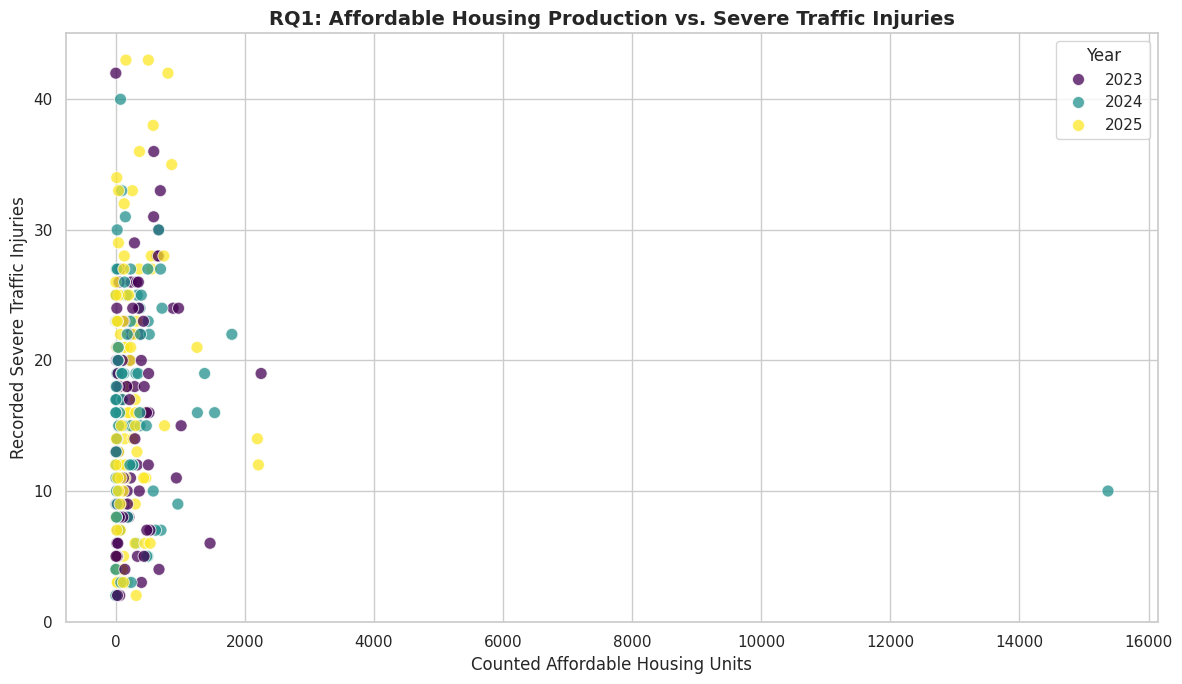

In [53]:
# =====================================================
# RQ1 — AFFORDABLE HOUSING VS SEVERE INJURIES
# =====================================================

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=rq1_data,
    x="Affordable_Units",
    y="Severe_Injuries",
    hue="Year",
    palette="viridis",
    s=75,
    alpha=0.75
)

plt.title(
    "RQ1: Affordable Housing Production vs. Severe Traffic Injuries",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Counted Affordable Housing Units")
plt.ylabel("Recorded Severe Traffic Injuries")

plt.legend(title="Year")

plt.tight_layout()
plt.show()

In [54]:
# =====================================================
# RQ1 — GEOGRAPHIC AMBIGUITY SENSITIVITY CHECK
# =====================================================

rq1_unambiguous = rq1_data[
    ~rq1_data["Geographic_Ambiguity"]
].copy()

print("Original observations:", len(rq1_data))
print("Unambiguous observations:", len(rq1_unambiguous))

if len(rq1_unambiguous) >= 3:

    pearson_clean, _ = pearsonr(
        rq1_unambiguous["Affordable_Units"],
        rq1_unambiguous["Severe_Injuries"]
    )

    spearman_clean, _ = spearmanr(
        rq1_unambiguous["Affordable_Units"],
        rq1_unambiguous["Severe_Injuries"]
    )

    sensitivity_results = pd.DataFrame({
        "Method": ["Pearson", "Spearman"],
        "All_Observations": [
            pearson_corr,
            spearman_corr
        ],
        "Without_Geographic_Ambiguity": [
            pearson_clean,
            spearman_clean
        ]
    })

    display(sensitivity_results)

Original observations: 290
Unambiguous observations: 288


,Method,All_Observations,Without_Geographic_Ambiguity
0,Pearson,0.014225,0.013825
1,Spearman,0.218175,0.218860


### RQ1 Findings and Interpretation

The analysis included 290 matched ZIP-year observations across
122 ZIP codes during 2023–2025.

**Pearson Correlation:** 0.0142 (p = 0.8094)

**Spearman Correlation:** 0.2182 (p = 0.000181)

The Pearson result indicates almost no linear relationship between
counted affordable housing units and recorded severe traffic injuries.

However, the Spearman result suggests a weak positive monotonic
association. ZIP-year observations with greater affordable housing
production tend to rank somewhat higher in recorded severe injuries.

The difference between the two correlation measures may be influenced
by the strongly right-skewed housing distribution and extreme values,
including an observation containing 15,372 counted units.

Removing geographically ambiguous observations produced negligible
changes in either correlation coefficient.

**Conclusion:**

There is little evidence of a linear relationship between affordable
housing production and recorded severe injuries, although a weak
positive rank-based association is observed.

**Limitations:**

- Correlation does not establish causation.
- The analysis includes only ZIP-year observations present in both datasets.
- SIRTA does not represent every traffic crash in NYC.
- Geographic coverage is incomplete.
- The analysis uses raw injury counts without population or traffic
  exposure adjustments.
- Repeated ZIP codes across years violate the independence assumption
  of conventional correlation significance tests.

The findings should therefore be interpreted as exploratory
geographic-temporal associations.

### RQ2: Borough-Level Differences in Housing and Traffic Safety

**Research Question:**

How does the relationship between affordable housing production
and severe traffic injuries differ across New York City's boroughs?

**Motivation:**

Housing development and transportation conditions vary across
NYC boroughs. Therefore, citywide relationships may conceal
important geographic differences.

**Methodology:**

- Unit of analysis: ZIP code and year.
- Period: 2023–2025.
- Housing metric: Counted affordable housing units.
- Transportation metric: Recorded severe traffic injuries.
- Geographic grouping: NYC borough.
- Visualization: Faceted scatter plots.
- Statistical analysis: Spearman correlation by borough.

Only observations with complete housing-unit measurements
and unambiguous geographic classification are included.

The analysis is exploratory and does not establish causation.

In [55]:
# =====================================================
# RQ2 — PREPARE BOROUGH-LEVEL DATA
# =====================================================

rq2_data = final_dataset[
    final_dataset["Year"].between(2023, 2025)
    &
    final_dataset["Housing_Data_Complete"]
    &
    ~final_dataset["Geographic_Ambiguity"]
].copy()

borough_summary = (
    rq2_data
    .groupby("Borough")
    .agg(
        Observations=("ZIP_Code", "size"),
        Unique_ZIP_Codes=("ZIP_Code", "nunique"),
        Affordable_Units=("Affordable_Units", "sum"),
        Severe_Injuries=("Severe_Injuries", "sum")
    )
    .reset_index()
)

print("RQ2 — BOROUGH ANALYSIS SUMMARY")

display(borough_summary)

RQ2 — BOROUGH ANALYSIS SUMMARY


,Borough,Observations,Unique_ZIP_Codes,Affordable_Units,Severe_Injuries
0,Bronx,64,23,41290.0,1210.0
1,Brooklyn,91,36,17808.0,1758.0
2,Manhattan,66,29,14096.0,901.0
3,Queens,63,30,13096.0,781.0
4,Staten Island,4,3,137.0,45.0


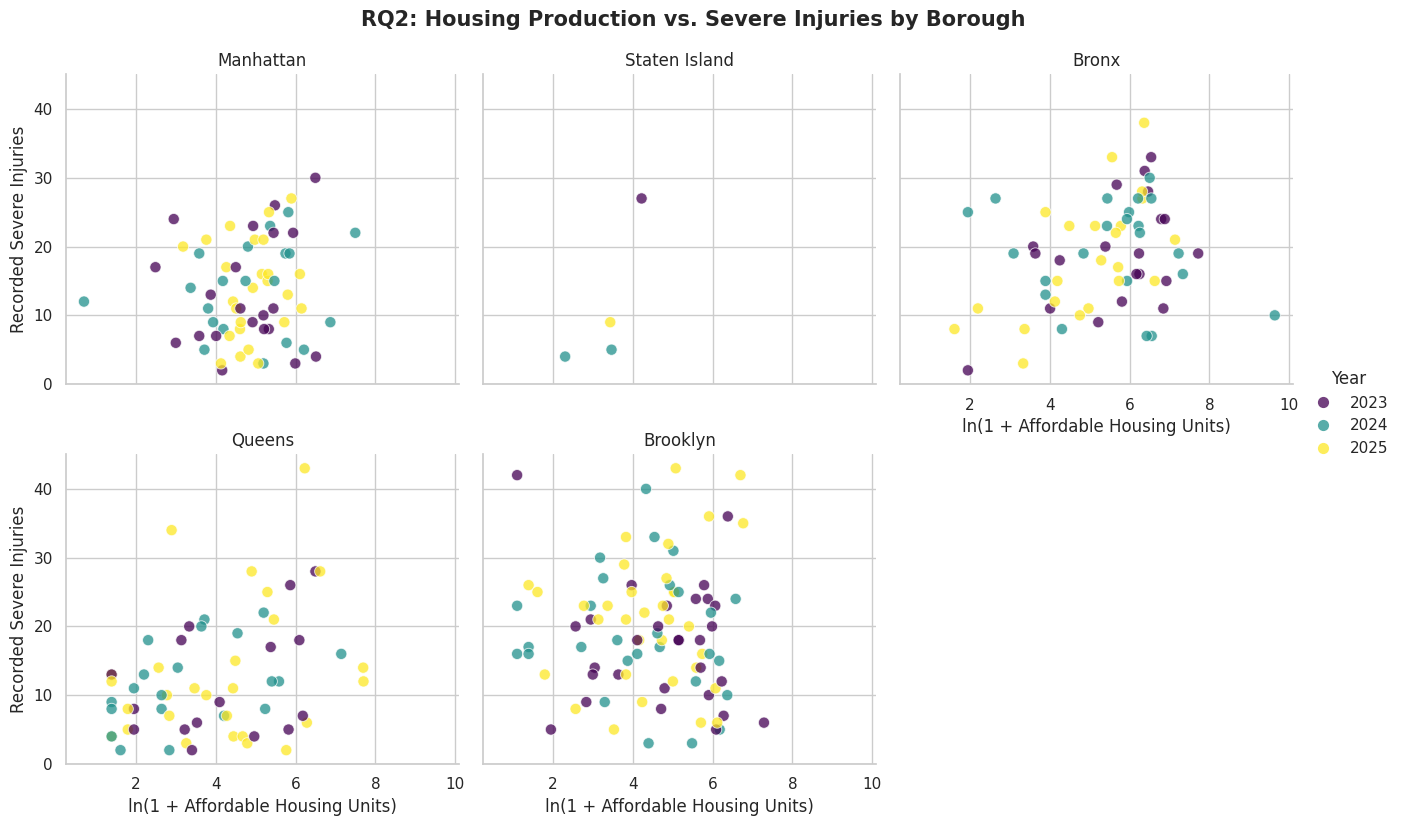

In [56]:
# =====================================================
# RQ2 — FACETED SCATTER PLOTS
# =====================================================

rq2_data["Log_Affordable_Units"] = np.log1p(
    rq2_data["Affordable_Units"]
)

g = sns.relplot(
    data=rq2_data,
    x="Log_Affordable_Units",
    y="Severe_Injuries",
    col="Borough",
    col_wrap=3,
    hue="Year",
    kind="scatter",
    height=4,
    aspect=1.1,
    alpha=0.75,
    s=65,
    palette="viridis"
)

g.set_axis_labels(
    "ln(1 + Affordable Housing Units)",
    "Recorded Severe Injuries"
)

g.set_titles("{col_name}")

g.figure.suptitle(
    "RQ2: Housing Production vs. Severe Injuries by Borough",
    y=1.03,
    fontsize=15,
    fontweight="bold"
)

plt.show()

In [57]:
# =====================================================
# RQ2 — SPEARMAN CORRELATION BY BOROUGH
# =====================================================

from scipy.stats import spearmanr

borough_correlations = []

for borough, group in rq2_data.groupby("Borough"):

    n = len(group)

    # Avoid unreliable or undefined calculations
    if (
        n < 5
        or group["Affordable_Units"].nunique() < 2
        or group["Severe_Injuries"].nunique() < 2
    ):
        correlation = np.nan
        p_value = np.nan
    else:
        correlation, p_value = spearmanr(
            group["Affordable_Units"],
            group["Severe_Injuries"]
        )

    borough_correlations.append({
        "Borough": borough,
        "Observations": n,
        "Spearman_Correlation": correlation,
        "Exploratory_P_Value": p_value
    })

borough_correlation_results = pd.DataFrame(
    borough_correlations
)

print("RQ2 — BOROUGH-LEVEL CORRELATIONS")

display(
    borough_correlation_results.sort_values(
        "Spearman_Correlation",
        ascending=False
    )
)

RQ2 — BOROUGH-LEVEL CORRELATIONS


,Borough,Observations,Spearman_Correlation,Exploratory_P_Value
3,Queens,63,0.294639,0.019074
0,Bronx,64,0.261917,0.036556
2,Manhattan,66,0.151973,0.223174
1,Brooklyn,91,-0.056850,0.592477
4,Staten Island,4,NaN,NaN


### RQ2 Findings and Interpretation

The borough-level analysis includes 288 matched ZIP-year observations
from 2023–2025 after excluding incomplete housing measurements
and geographically ambiguous observations.

**Finding 1: Queens has the strongest positive association.**

Queens exhibits a Spearman correlation of approximately 0.295,
suggesting a weak positive monotonic association between counted
affordable housing units and recorded severe traffic injuries.

**Finding 2: The Bronx also exhibits a positive association.**

The Bronx has a Spearman correlation of approximately 0.262,
indicating a weak positive relationship between the two metrics.

**Finding 3: Manhattan exhibits a weaker association.**

Manhattan has a Spearman correlation of approximately 0.152.

**Finding 4: Brooklyn exhibits almost no monotonic association.**

Brooklyn has a Spearman correlation of approximately -0.057,
suggesting little association between affordable housing units
and severe injuries within the observed ZIP-year combinations.

**Finding 5: Staten Island has insufficient observations.**

Only four observations are available for Staten Island, making
reliable borough-level correlation analysis inappropriate.

**Conclusion:**

The association between affordable housing production and recorded
severe traffic injuries varies across NYC boroughs.

Queens and the Bronx exhibit weak positive monotonic associations,
while Brooklyn and Manhattan show little or weaker association.

**Limitations:**

- The observations represent matched ZIP-year combinations rather
  than all neighborhoods in NYC.
- Geographic coverage varies substantially between boroughs.
- The sample contains repeated ZIP codes across years.
- Conventional correlation p-values should be treated as exploratory.
- The analysis uses raw injury counts without population or traffic
  exposure adjustments.
- Differences between borough correlations have not been formally tested.
- Correlation does not establish causation.

These findings suggest that geographic context matters when
investigating housing development and transportation safety.

### RQ3: Temporal Patterns in Housing and Traffic Safety

**Research Question:**

How did affordable housing production and recorded severe traffic
injuries change across matched NYC ZIP codes between 2023 and 2025?

**Motivation:**

Annual changes in housing production and transportation safety
may reveal whether both domains follow similar or different trends.

**Methodology:**

- Period: 2023–2025.
- Unit of analysis: ZIP code and year.
- Housing metric: Counted affordable housing units.
- Transportation metric: Recorded severe traffic injuries.
- Visualization: Indexed line chart (2023 = 100).

A balanced ZIP-code panel is used to ensure that the same ZIP
codes are compared across all three years.

This avoids interpreting changes in geographic sample composition
as genuine temporal changes.

**Limitations:**

The analysis includes only ZIP codes with complete matched
observations in all three years.

SIRTA geographic coverage remains incomplete, and annual housing
production can fluctuate because of large individual projects.

In [58]:
# =====================================================
# RQ3 — BUILD BALANCED ZIP-CODE PANEL
# =====================================================

rq3_source = final_dataset[
    final_dataset["Year"].between(2023, 2025)
    &
    final_dataset["Housing_Data_Complete"]
    &
    ~final_dataset["Geographic_Ambiguity"]
].copy()

# Count the number of distinct years for each ZIP code
zip_year_coverage = (
    rq3_source
    .groupby("ZIP_Code")["Year"]
    .nunique()
)

# Keep ZIP codes represented in all three years
balanced_zips = zip_year_coverage[
    zip_year_coverage == 3
].index

rq3_data = rq3_source[
    rq3_source["ZIP_Code"].isin(balanced_zips)
].copy()

print("=" * 60)
print("RQ3 — BALANCED PANEL SUMMARY")
print("=" * 60)

print("ZIP codes represented in all 3 years:",
      len(balanced_zips))

print("Total ZIP-year observations:",
      len(rq3_data))

print("\nObservations per year:")

display(
    rq3_data["Year"]
    .value_counts()
    .sort_index()
)

RQ3 — BALANCED PANEL SUMMARY
ZIP codes represented in all 3 years: 67
Total ZIP-year observations: 201

Observations per year:


,count
Year,
2023,67
2024,67
2025,67


In [59]:
# =====================================================
# RQ3 — ANNUAL HOUSING AND INJURY TRENDS
# =====================================================

rq3_annual = (
    rq3_data
    .groupby("Year")
    .agg(
        Affordable_Units=("Affordable_Units", "sum"),
        Severe_Injuries=("Severe_Injuries", "sum"),
        ZIP_Codes=("ZIP_Code", "nunique")
    )
    .reset_index()
    .sort_values("Year")
)

print("RQ3 — ANNUAL SUMMARY")

display(rq3_annual)

RQ3 — ANNUAL SUMMARY


,Year,Affordable_Units,Severe_Injuries,ZIP_Codes
0,2023,21043.0,1071.0,67
1,2024,18969.0,1223.0,67
2,2025,18301.0,1274.0,67


RQ3 — INDEXED TEMPORAL RESULTS


,Year,Affordable_Units,Severe_Injuries,ZIP_Codes,Housing_Index,Severe_Injury_Index
0,2023,21043.0,1071.0,67,100.000000,100.000000
1,2024,18969.0,1223.0,67,90.143991,114.192344
2,2025,18301.0,1274.0,67,86.969539,118.954248


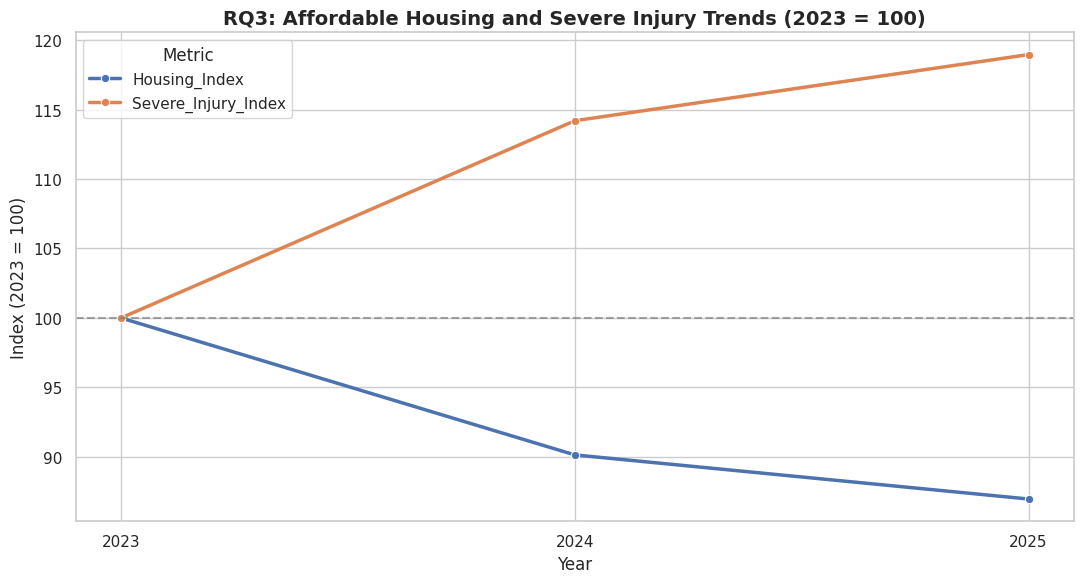

In [60]:
# =====================================================
# RQ3 — INDEXED TEMPORAL COMPARISON
# =====================================================

rq3_indexed = rq3_annual.copy()

# Identify baseline values from 2023
baseline = rq3_indexed[
    rq3_indexed["Year"] == 2023
].iloc[0]

# Validate positive baselines
assert baseline["Affordable_Units"] > 0
assert baseline["Severe_Injuries"] > 0

# Calculate index values
rq3_indexed["Housing_Index"] = (
    rq3_indexed["Affordable_Units"]
    /
    baseline["Affordable_Units"]
    * 100
)

rq3_indexed["Severe_Injury_Index"] = (
    rq3_indexed["Severe_Injuries"]
    /
    baseline["Severe_Injuries"]
    * 100
)

print("RQ3 — INDEXED TEMPORAL RESULTS")

display(rq3_indexed)

# Convert data to long format for visualization
rq3_plot = rq3_indexed.melt(
    id_vars="Year",
    value_vars=[
        "Housing_Index",
        "Severe_Injury_Index"
    ],
    var_name="Metric",
    value_name="Index"
)

# Create line chart
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=rq3_plot,
    x="Year",
    y="Index",
    hue="Metric",
    marker="o",
    linewidth=2.5
)

plt.axhline(
    y=100,
    linestyle="--",
    color="gray",
    alpha=0.7
)

plt.title(
    "RQ3: Affordable Housing and Severe Injury Trends (2023 = 100)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Index (2023 = 100)")
plt.xticks([2023, 2024, 2025])

plt.tight_layout()
plt.show()


### RQ3 Findings and Interpretation

The temporal analysis used a balanced panel of 67 NYC ZIP codes
represented in all three years from 2023 to 2025.

**Finding 1: Counted affordable housing units decreased.**

Housing units associated with completed projects declined from
21,043 in 2023 to 18,301 in 2025, a decrease of approximately 13%.

**Finding 2: Recorded severe traffic injuries increased.**

Severe injuries increased from 1,071 in 2023 to 1,274 in 2025,
representing an increase of approximately 19%.

**Finding 3: The two indicators followed opposing trends.**

The indexed chart shows declining affordable housing completion
activity alongside increasing recorded severe injuries within
the same 67 ZIP codes.

**Conclusion:**

The selected geographic areas exhibited diverging trends in
affordable housing completion activity and recorded severe
traffic injuries during 2023–2025.

This finding does not establish a causal relationship.

**Limitations:**

- The analysis includes only 67 ZIP codes with matching observations
  in all three years.
- The balanced panel does not correct for missing SIRTA geographic data.
- Housing completion totals include preservation activity and do
  not measure the existing affordable housing stock.
- Yearly housing activity may fluctuate because of large projects.
- Changes in traffic exposure and population are not controlled.
- Three annual observations are insufficient to establish a
  long-term trend.



### RQ4: Identifying Housing and Traffic Safety Hotspots

**Research Question:**

Which NYC ZIP codes exhibit both relatively high affordable housing
production and high recorded severe traffic injuries in 2025?

**Methodology:**

- Geographic unit: ZIP code.
- Analysis year: 2025.
- Housing metric: Counted affordable housing units.
- Transportation metric: Recorded severe traffic injuries.
- Visualization: Quadrant scatter plot.
- Classification method: Median thresholds.

ZIP codes are classified into four groups:

1. High Housing / High Injuries
2. High Housing / Low Injuries
3. Low Housing / High Injuries
4. Low Housing / Low Injuries

The thresholds describe the selected sample rather than official
risk or urban-planning standards.

Only matched observations with complete housing measurements and
unambiguous borough classifications are included.


In [61]:
# =====================================================
# RQ4 — IDENTIFY HOUSING AND INJURY HOTSPOTS
# =====================================================

rq4_data = final_dataset[
    (final_dataset["Year"] == 2025)
    & (final_dataset["Housing_Data_Complete"])
    & (~final_dataset["Geographic_Ambiguity"])
].copy()

# Calculate median thresholds
housing_threshold = rq4_data["Affordable_Units"].median()
injury_threshold = rq4_data["Severe_Injuries"].median()

# Classify ZIP codes into four groups
conditions = [
    (rq4_data["Affordable_Units"] >= housing_threshold)
    & (rq4_data["Severe_Injuries"] >= injury_threshold),

    (rq4_data["Affordable_Units"] >= housing_threshold)
    & (rq4_data["Severe_Injuries"] < injury_threshold),

    (rq4_data["Affordable_Units"] < housing_threshold)
    & (rq4_data["Severe_Injuries"] >= injury_threshold)
]

categories = [
    "High Housing / High Injuries",
    "High Housing / Low Injuries",
    "Low Housing / High Injuries"
]

rq4_data["Category"] = np.select(
    conditions,
    categories,
    default="Low Housing / Low Injuries"
)

print("RQ4 — 2025 ANALYSIS SUMMARY")

print("ZIP codes:", len(rq4_data))
print("Housing median threshold:", housing_threshold)
print("Severe injury median threshold:", injury_threshold)

display(rq4_data["Category"].value_counts())

# Identify ZIP codes in the high-high quadrant
high_high_zips = rq4_data[
    rq4_data["Category"] == "High Housing / High Injuries"
].sort_values(
    ["Severe_Injuries", "Affordable_Units"],
    ascending=False
)

print("\nHIGH HOUSING / HIGH INJURY ZIP CODES")

display(
    high_high_zips[
        [
            "ZIP_Code",
            "Borough",
            "Affordable_Units",
            "Severe_Injuries",
            "Fatalities"
        ]
    ].head(15)
)

RQ4 — 2025 ANALYSIS SUMMARY
ZIP codes: 109
Housing median threshold: 115.0
Severe injury median threshold: 15.0


,count
Category,
High Housing / High Injuries,37
Low Housing / Low Injuries,33
Low Housing / High Injuries,21
High Housing / Low Injuries,18



HIGH HOUSING / HIGH INJURY ZIP CODES


,ZIP_Code,Borough,Affordable_Units,Severe_Injuries,Fatalities
309,11355,Queens,506.0,43.0,1.0
288,11234,Brooklyn,159.0,43.0,3.0
226,11212,Brooklyn,810.0,42.0,3.0
110,10456,Bronx,581.0,38.0,1.0
206,11206,Brooklyn,368.0,36.0,1.0
214,11208,Brooklyn,868.0,35.0,3.0
144,10467,Bronx,259.0,33.0,2.0
271,11226,Brooklyn,132.0,32.0,0.0
173,11101,Queens,746.0,28.0,1.0
114,10457,Bronx,551.0,28.0,0.0


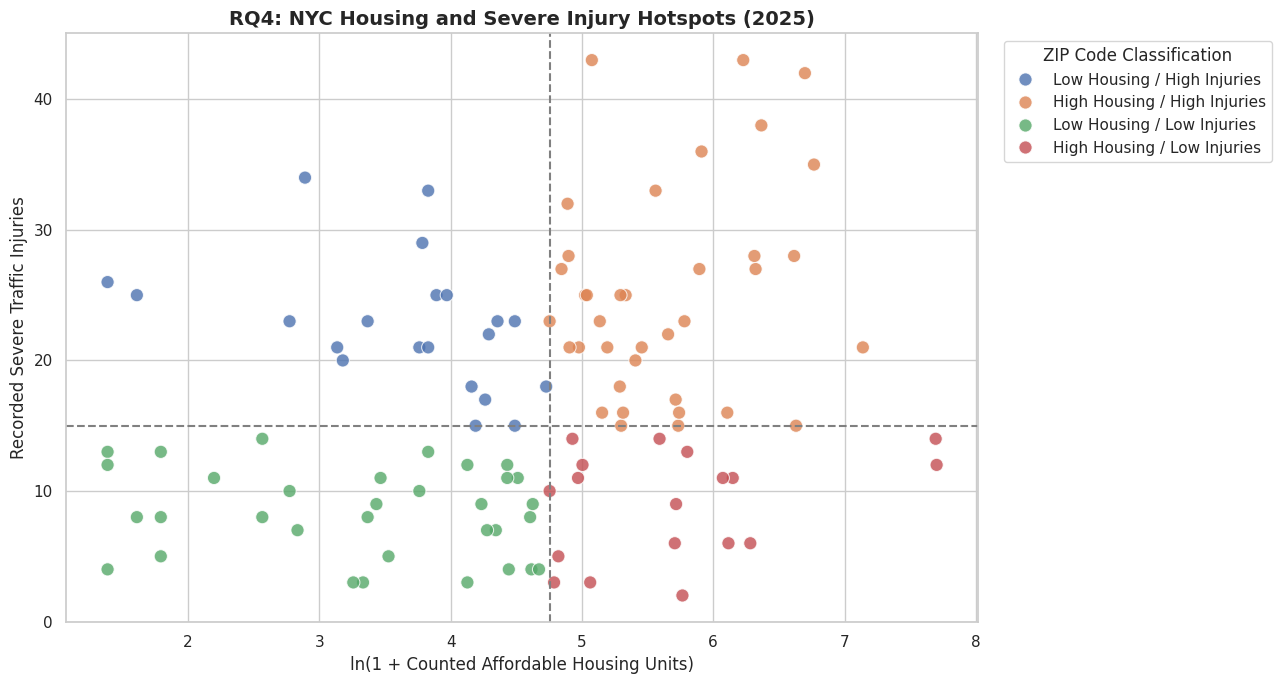

In [62]:
# =====================================================
# RQ4 — QUADRANT SCATTER PLOT
# =====================================================

rq4_data["Log_Housing"] = np.log1p(
    rq4_data["Affordable_Units"]
)

log_threshold = np.log1p(housing_threshold)

plt.figure(figsize=(13, 7))

sns.scatterplot(
    data=rq4_data,
    x="Log_Housing",
    y="Severe_Injuries",
    hue="Category",
    s=90,
    alpha=0.8
)

# Median-based quadrant boundaries
plt.axvline(
    log_threshold,
    color="gray",
    linestyle="--"
)

plt.axhline(
    injury_threshold,
    color="gray",
    linestyle="--"
)

plt.title(
    "RQ4: NYC Housing and Severe Injury Hotspots (2025)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("ln(1 + Counted Affordable Housing Units)")
plt.ylabel("Recorded Severe Traffic Injuries")

plt.legend(
    title="ZIP Code Classification",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


### RQ4 Findings and Interpretation

The hotspot analysis examined 109 matched NYC ZIP codes in 2025.

The classification used median thresholds of 115 counted affordable
housing units and 15 recorded severe traffic injuries.

**Classification Results:**

- High Housing / High Injuries: 37 ZIP codes
- Low Housing / Low Injuries: 33 ZIP codes
- Low Housing / High Injuries: 21 ZIP codes
- High Housing / Low Injuries: 18 ZIP codes

**Finding 1: High housing activity and high severe injury counts
coincide in several ZIP codes.**

A total of 37 ZIP codes were classified in the High Housing /
High Injuries category.

**Finding 2: Several locations stand out.**

ZIP code 11355 in Queens recorded 506 counted affordable housing
units and 43 severe injuries.

ZIP code 11212 in Brooklyn recorded 810 counted affordable housing
units and 42 severe injuries.

These locations may warrant further examination of transportation
safety conditions alongside housing development activity.

**Finding 3: The relationship is not uniform.**

Other ZIP codes exhibit high housing activity with relatively
low injury counts, or low housing activity with high injury counts.

**Conclusion:**

The analysis identifies 37 ZIP codes where relatively high
affordable housing completion activity coincides with relatively
high recorded severe traffic injury counts in 2025.

**Limitations:**

- Median thresholds are relative to the selected sample and are
  not official safety-risk thresholds.
- The analysis uses raw counts without population or traffic
  exposure adjustments.
- Only matched ZIP codes with complete housing measurements and
  unambiguous geographic classifications are included.
- The dataset contains incomplete geographic coverage.
- The observed co-occurrence does not establish causation.



### RQ5: Affordable Housing Production and Traffic Fatalities

**Research Question:**

Are ZIP-year observations with greater affordable housing production
associated with higher recorded traffic fatalities?

**Motivation:**

Traffic fatalities represent a particularly serious transportation
safety outcome. Examining fatalities separately from severe injuries
may reveal different geographic-temporal associations.

**Methodology:**

- Period: 2023–2025.
- Unit of analysis: ZIP code and year.
- Housing metric: Counted affordable housing units.
- Transportation metric: Recorded traffic fatalities.
- Visualization: Scatter plot with logarithmically transformed
  housing values.
- Statistical methods: Pearson and Spearman correlations.

The analysis excludes incomplete housing-unit observations
and geographically ambiguous records.

Results are exploratory and do not establish causation.


In [63]:
# =====================================================
# RQ5 — PREPARE DATA AND CALCULATE CORRELATIONS
# =====================================================

from scipy.stats import pearsonr, spearmanr

rq5_data = final_dataset[
    final_dataset["Year"].between(2023, 2025)
    & final_dataset["Housing_Data_Complete"]
    & ~final_dataset["Geographic_Ambiguity"]
].copy()

# Keep valid measurements
rq5_data = rq5_data[
    (rq5_data["Affordable_Units"] >= 0) &
    (rq5_data["Fatalities"] >= 0)
].copy()

# Calculate correlations
pearson_r, pearson_p = pearsonr(
    rq5_data["Affordable_Units"],
    rq5_data["Fatalities"]
)

spearman_r, spearman_p = spearmanr(
    rq5_data["Affordable_Units"],
    rq5_data["Fatalities"]
)

rq5_results = pd.DataFrame({
    "Method": ["Pearson", "Spearman"],
    "Correlation": [pearson_r, spearman_r],
    "P_Value": [pearson_p, spearman_p]
})

print("RQ5 — HOUSING AND FATALITIES")

print("Observations:", len(rq5_data))
print("Unique ZIP codes:", rq5_data["ZIP_Code"].nunique())

display(rq5_results)

print("\nFatality Distribution:")

display(rq5_data["Fatalities"].describe())

RQ5 — HOUSING AND FATALITIES
Observations: 288
Unique ZIP codes: 121


,Method,Correlation,P_Value
0,Pearson,-0.050410,0.394045
1,Spearman,0.016052,0.786199



Fatality Distribution:


,Fatalities
count,288.000000
mean,1.079861
std,1.137212
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,5.000000


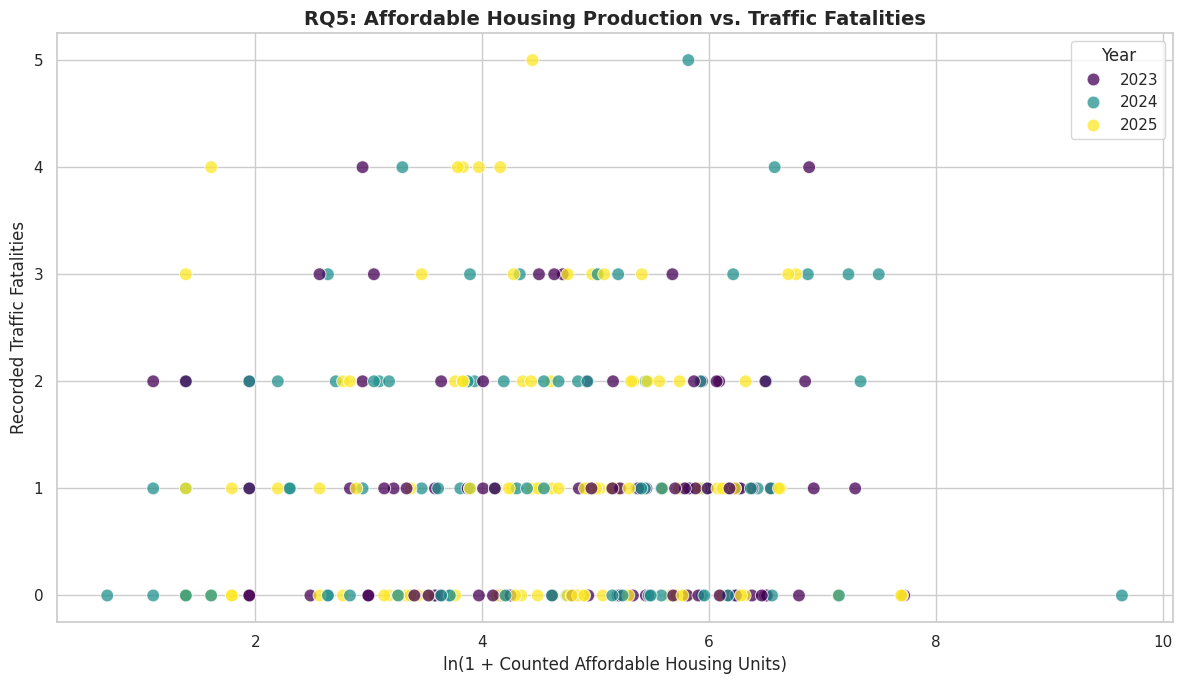

In [64]:
# =====================================================
# RQ5 — HOUSING VS TRAFFIC FATALITIES
# =====================================================

rq5_data["Log_Housing"] = np.log1p(
    rq5_data["Affordable_Units"]
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=rq5_data,
    x="Log_Housing",
    y="Fatalities",
    hue="Year",
    palette="viridis",
    s=85,
    alpha=0.75
)

plt.title(
    "RQ5: Affordable Housing Production vs. Traffic Fatalities",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("ln(1 + Counted Affordable Housing Units)")
plt.ylabel("Recorded Traffic Fatalities")

plt.tight_layout()
plt.show()


### RQ5 Findings and Interpretation

The analysis examined 288 matched ZIP-year observations across
121 NYC ZIP codes during 2023–2025.

**Pearson Correlation:** -0.0504 (p = 0.3940)

**Spearman Correlation:** 0.0161 (p = 0.7862)

**Finding 1: No meaningful linear association was observed.**

The Pearson correlation is very close to zero, indicating little
linear relationship between affordable housing production and
recorded traffic fatalities.

**Finding 2: No meaningful monotonic association was observed.**

The Spearman correlation is also approximately zero, indicating
little rank-based association between the two measurements.

**Finding 3: Fatalities show a different pattern from severe injuries.**

RQ1 identified a weak positive Spearman association between
housing production and severe injuries.

In contrast, RQ5 identified almost no monotonic association
between housing production and fatalities.

However, no formal test was performed to establish whether these
two associations differ statistically.

**Conclusion:**

The selected dataset provides little evidence of a meaningful
linear or monotonic relationship between counted affordable
housing units and recorded traffic fatalities.

**Limitations:**

- The analysis uses raw fatality counts rather than exposure-adjusted rates.
- Fatality counts contain many tied values.
- ZIP codes can appear in multiple years.
- Conventional correlation p-values should be treated as exploratory.
- Geographic coverage of SIRTA records is incomplete.
- Correlation does not establish causation.



### RQ6: Housing Production Intensity and Severe Injury Distributions

**Research Question:**

Do ZIP-year observations with different levels of affordable housing
production exhibit different distributions of recorded severe injuries?

**Methodology:**

- Period: 2023–2025.
- Unit of analysis: ZIP code and year.
- Housing metric: Counted affordable housing units.
- Transportation metric: Recorded severe injuries.
- Groups: Low, Medium, and High housing production.
- Visualization: Box plot.

Housing groups are calculated using sample-based tertiles.

This descriptive comparison does not establish causation.


RQ6 — HOUSING INTENSITY GROUPS


,Housing_Group,Observations,Median_Housing_Units,Median_Severe_Injuries,Mean_Severe_Injuries
0,Low,96,19.0,13.0,14.427083
1,Medium,96,122.0,16.5,16.104167
2,High,96,476.5,17.5,18.375000


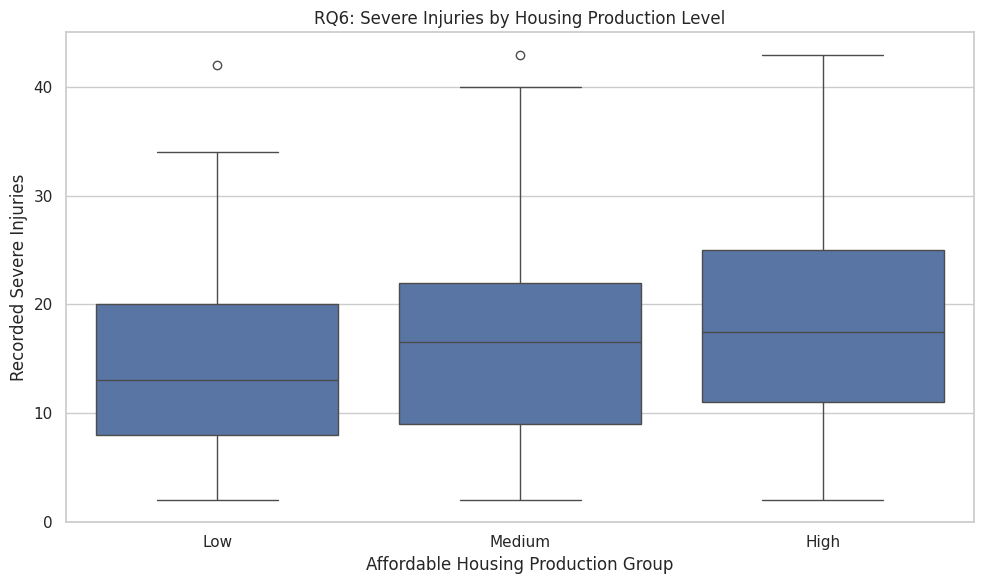

In [65]:
# =====================================================
# RQ6 — HOUSING INTENSITY VS SEVERE INJURIES
# =====================================================

rq6_data = final_dataset[
    final_dataset["Year"].between(2023, 2025)
    & final_dataset["Housing_Data_Complete"]
    & ~final_dataset["Geographic_Ambiguity"]
].copy()

# Divide observations into approximately equal-sized groups
rq6_data["Housing_Group"] = pd.qcut(
    rq6_data["Affordable_Units"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

rq6_summary = (
    rq6_data.groupby("Housing_Group", observed=True)
    .agg(
        Observations=("ZIP_Code", "size"),
        Median_Housing_Units=("Affordable_Units", "median"),
        Median_Severe_Injuries=("Severe_Injuries", "median"),
        Mean_Severe_Injuries=("Severe_Injuries", "mean")
    )
    .reset_index()
)

print("RQ6 — HOUSING INTENSITY GROUPS")
display(rq6_summary)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=rq6_data,
    x="Housing_Group",
    y="Severe_Injuries",
    order=["Low", "Medium", "High"]
)

plt.title("RQ6: Severe Injuries by Housing Production Level")
plt.xlabel("Affordable Housing Production Group")
plt.ylabel("Recorded Severe Injuries")

plt.tight_layout()
plt.show()


### RQ7: Construction Type and Severe Traffic Injuries

**Research Question:**

Does the association between housing activity and recorded severe
traffic injuries differ between New Construction and Preservation?

**Methodology:**

- Period: 2023–2025.
- Unit of analysis: ZIP code and year.
- Housing measurements: New Construction Units and Preservation Units.
- Transportation measurement: Recorded Severe Injuries.
- Visualization: Two-panel scatter plot.
- Statistical measure: Spearman correlation.

Only ZIP-year observations containing positive units in the
respective construction category are used for each comparison.

Both construction types may occur within the same ZIP-year.
The two groups are therefore not necessarily independent.

Results are exploratory.


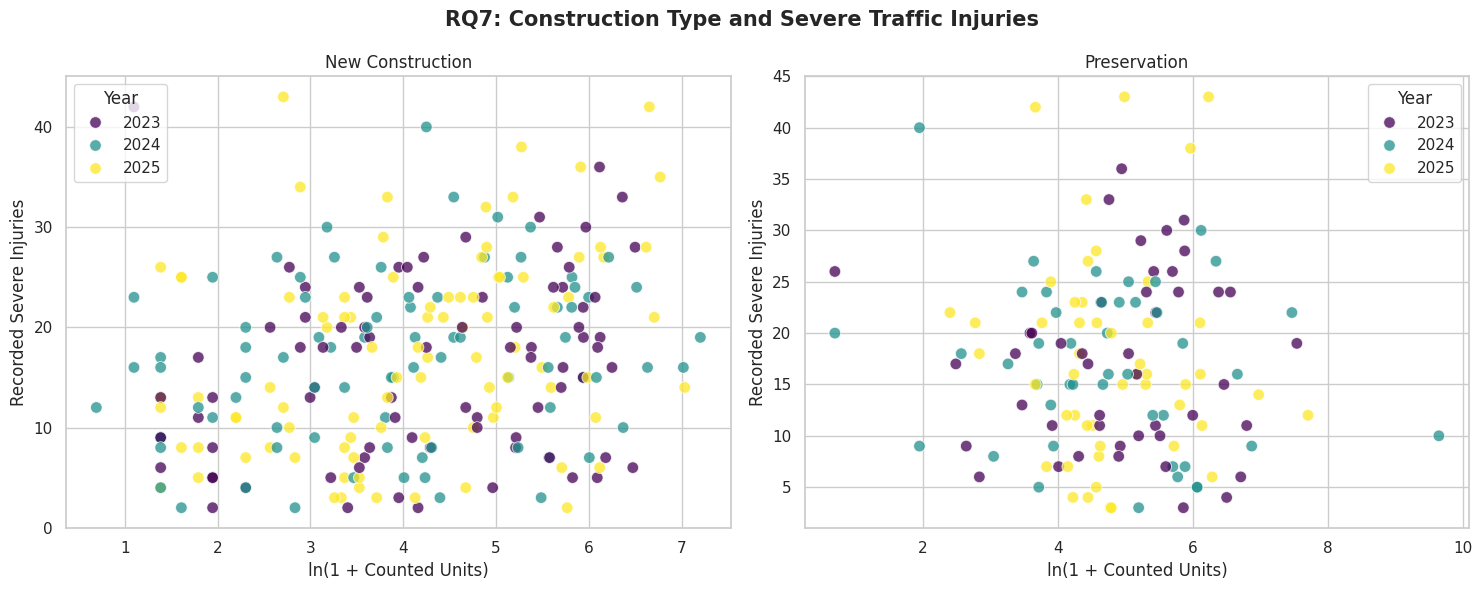

RQ7 — CORRELATION RESULTS


,Construction_Type,Observations,Spearman_Correlation
0,New Construction,253,0.262807
1,Preservation,138,-0.046476


In [66]:
# =====================================================
# RQ7 — CONSTRUCTION TYPE VS SEVERE INJURIES
# =====================================================

rq7_data = final_dataset[
    final_dataset["Year"].between(2023, 2025)
    & final_dataset["Housing_Data_Complete"]
    & ~final_dataset["Geographic_Ambiguity"]
].copy()

construction_metrics = {
    "New Construction": "New_Construction_Units",
    "Preservation": "Preservation_Units"
}

rq7_results = []

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (label, column) in zip(
    axes, construction_metrics.items()
):
    subset = rq7_data[
        rq7_data[column] > 0
    ].copy()

    subset["Log_Units"] = np.log1p(subset[column])

    sns.scatterplot(
        data=subset,
        x="Log_Units",
        y="Severe_Injuries",
        hue="Year",
        palette="viridis",
        alpha=0.75,
        s=70,
        ax=ax
    )

    correlation = (
        spearmanr(
            subset[column],
            subset["Severe_Injuries"]
        ).statistic
        if len(subset) >= 5
        and subset[column].nunique() > 1
        and subset["Severe_Injuries"].nunique() > 1
        else np.nan
    )

    rq7_results.append({
        "Construction_Type": label,
        "Observations": len(subset),
        "Spearman_Correlation": correlation
    })

    ax.set_title(label)
    ax.set_xlabel("ln(1 + Counted Units)")
    ax.set_ylabel("Recorded Severe Injuries")

fig.suptitle(
    "RQ7: Construction Type and Severe Traffic Injuries",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("RQ7 — CORRELATION RESULTS")
display(pd.DataFrame(rq7_results))


### RQ8: Year-to-Year Changes in Housing and Traffic Safety

**Research Question:**

Are year-to-year changes in counted affordable housing units
associated with changes in recorded severe traffic injuries
within the same NYC ZIP codes?

**Methodology:**

- Period: 2023–2025.
- Unit of analysis: ZIP code and year-to-year transition.
- Housing variable: Change in counted affordable units.
- Transportation variable: Change in recorded severe injuries.
- Visualization: Change-versus-change scatter plot.
- Statistical measure: Spearman correlation.

Only ZIP codes represented in all three years are included.

Changes are calculated as current-year values minus previous-year
values for each ZIP code.

The analysis is descriptive and does not establish causation.


RQ8 — CHANGE ANALYSIS
Observations: 134
ZIP Codes: 67


,Housing_Change,Injury_Change
count,134.000000,134.000000
mean,-20.462687,1.514925
std,412.157092,6.849329
min,-1438.000000,-16.000000
25%,-165.500000,-2.000000
50%,-16.500000,2.000000
75%,96.750000,6.000000
max,2208.000000,17.000000



Spearman Correlation: 0.0584
Exploratory P-value: 0.503


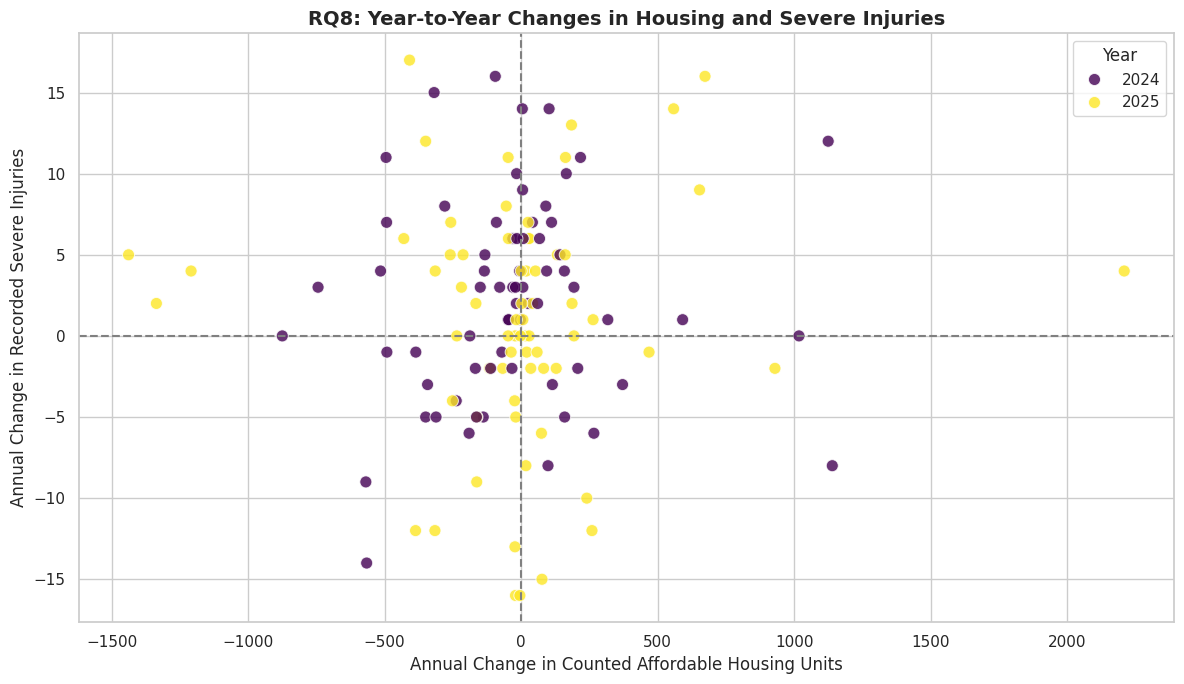

In [67]:
# =====================================================
# RQ8 — YEAR-TO-YEAR CHANGE ANALYSIS
# =====================================================

rq8_data = rq3_data.copy()

rq8_data = rq8_data.sort_values(
    ["ZIP_Code", "Year"]
)

# Calculate within-ZIP annual changes
rq8_data["Housing_Change"] = (
    rq8_data.groupby("ZIP_Code")["Affordable_Units"]
    .diff()
)

rq8_data["Injury_Change"] = (
    rq8_data.groupby("ZIP_Code")["Severe_Injuries"]
    .diff()
)

# Remove first-year observations without previous values
rq8_changes = rq8_data.dropna(
    subset=["Housing_Change", "Injury_Change"]
).copy()

print("RQ8 — CHANGE ANALYSIS")

print("Observations:", len(rq8_changes))
print("ZIP Codes:", rq8_changes["ZIP_Code"].nunique())

display(
    rq8_changes[
        ["Housing_Change", "Injury_Change"]
    ].describe()
)

# Spearman correlation
rq8_spearman, rq8_p = spearmanr(
    rq8_changes["Housing_Change"],
    rq8_changes["Injury_Change"]
)

print("\nSpearman Correlation:", round(rq8_spearman, 4))
print("Exploratory P-value:", round(rq8_p, 4))

# Visualization
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=rq8_changes,
    x="Housing_Change",
    y="Injury_Change",
    hue="Year",
    palette="viridis",
    s=75,
    alpha=0.8
)

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.title(
    "RQ8: Year-to-Year Changes in Housing and Severe Injuries",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Annual Change in Counted Affordable Housing Units")
plt.ylabel("Annual Change in Recorded Severe Injuries")

plt.tight_layout()
plt.show()


### RQ6 Findings — Housing Production Groups

The analysis divided 288 matched ZIP-year observations into
three equally sized housing-production groups.

Median severe injuries increased from 13 in the Low Housing
group to 16.5 in the Medium group and 17.5 in the High group.

Mean severe injuries also increased across these groups,
from approximately 14.43 to 18.38.

**Conclusion:** ZIP-year observations with higher counted
affordable housing production generally exhibit somewhat higher
recorded severe injury counts in this sample.

However, the injury distributions overlap substantially.
These differences are descriptive and do not establish causation.

---

### RQ7 Findings — Construction Type Differences

New Construction observations (n = 253) exhibited a weak positive
Spearman association with severe injuries (r = 0.263).

Preservation observations (n = 138) exhibited almost no monotonic
association (r = -0.046).

**Conclusion:** The observed housing–injury association differs
between New Construction and Preservation subsets.

However, the samples can overlap, and no formal statistical test
of the difference between correlations was performed.

These results do not demonstrate that construction activity
causes traffic injuries.

---

### RQ8 Findings — Year-to-Year Changes

The analysis examined 134 year-to-year changes across 67
ZIP codes between 2023 and 2025.

The Spearman correlation between changes in counted affordable
housing units and changes in recorded severe injuries was 0.0584.

The exploratory p-value was approximately 0.503.

**Conclusion:** There is little evidence of a monotonic association
between year-to-year changes in the two measurements.

This suggests that the weak positive cross-sectional association
observed earlier does not translate into a clear relationship
between annual changes.

**Limitations Across RQ6–RQ8:**

- The analysis uses recorded counts without population or
  traffic exposure adjustments.
- Geographic coverage of SIRTA records is incomplete.
- Housing production includes both new construction and preservation.
- Repeated ZIP codes make conventional independence assumptions
  inappropriate.
- Large housing projects can influence aggregate measurements.
- These findings are exploratory and do not establish causation.



## 9. Overall Findings, Limitations, and Recommendations

### 9.1 Research Overview

This project investigated geographic and temporal relationships
between affordable housing production and serious traffic injuries
across New York City.

Two NYC Open Data datasets were integrated:

1. Affordable Housing Production by Building.
2. Serious Injury Response, Tracking & Analysis (SIRTA).

After data cleaning and aggregation, the datasets were integrated
using ZIP Code and Year.

The integration produced 367 matched ZIP-year observations
covering 2022–2025, of which 366 had complete housing-unit
measurements.

Eight research questions were investigated using descriptive
statistics, correlation analysis, and visualizations.

### 9.2 Summary of Key Findings

**Finding 1 — Overall Association (RQ1)**

The Pearson correlation between affordable housing units and
severe traffic injuries was approximately 0.014, suggesting
almost no linear association.

However, Spearman correlation was approximately 0.218,
indicating a weak positive rank-based association.

**Finding 2 — Geographic Differences (RQ2)**

The association varied across boroughs.

Queens (r = 0.295) and the Bronx (r = 0.262) exhibited weak
positive Spearman correlations, while Brooklyn showed
almost no association (r = -0.057).

Staten Island had insufficient observations for reliable
borough-level correlation analysis.

**Finding 3 — Temporal Trends (RQ3)**

Across a balanced panel of 67 ZIP codes, counted affordable
housing units decreased by approximately 13% between
2023 and 2025.

During the same period, recorded severe traffic injuries
increased by approximately 19%.

The two indicators therefore followed opposing trends
within the selected sample.

**Finding 4 — Geographic Hotspots (RQ4)**

In 2025, 37 of 109 analyzed ZIP codes were classified as
having both relatively high affordable housing production
and high recorded severe traffic injuries.

Examples included ZIP codes 11355 in Queens and 11212
in Brooklyn.

These classifications used sample-based median thresholds
rather than official safety-risk standards.

**Finding 5 — Fatalities (RQ5)**

The analysis identified almost no association between
affordable housing production and traffic fatalities.

Pearson correlation was approximately -0.050, while
Spearman correlation was approximately 0.016.

**Finding 6 — Housing Production Intensity (RQ6)**

Median severe injuries increased from 13 in the Low Housing
group to 16.5 in the Medium group and 17.5 in the High group.

However, the injury distributions overlapped substantially.

**Finding 7 — Construction Type (RQ7)**

New Construction exhibited a weak positive Spearman
association with severe injuries (r = 0.263).

Preservation exhibited almost no monotonic association
(r = -0.046).

The difference was descriptive and was not formally tested
for statistical significance.

**Finding 8 — Year-to-Year Changes (RQ8)**

The Spearman correlation between annual changes in counted
affordable housing units and severe injuries was approximately
0.058.

This suggests little evidence of an association between
year-to-year changes in these measurements.

### 9.3 Overall Interpretation

The findings indicate that relationships between affordable
housing production and recorded serious traffic injuries are
complex and vary across geographic areas and measurement types.

The overall linear association was nearly zero, while weak
positive rank-based associations were observed in some analyses.

Importantly, these associations did not translate into a clear
relationship between year-to-year changes in housing production
and severe injuries.

Traffic fatalities also exhibited little association with
affordable housing production.

Consequently, the findings do not support a simple conclusion
that greater affordable housing production is consistently
associated with more serious traffic injuries.

The results instead highlight the importance of geographic
context, construction type, and the specific transportation
safety metric being examined.



### 9.4 Research Limitations

The findings must be interpreted in light of several important
data and methodological limitations.

**1. Incomplete Geographic Coverage**

The SIRTA dataset contains substantial missing ZIP-code information.

Only approximately 16.3% of valid 2022 crash records had
usable ZIP codes. Geographic completeness improved in later
years but remained imperfect.

The housing dataset also exhibited uneven ZIP-code completeness,
particularly in Staten Island.

These missing values may introduce geographic selection bias.

**2. Limited Representation of NYC**

The integrated dataset contains only ZIP-year combinations
represented in both sources.

Consequently, the analytical sample does not include every
NYC neighborhood or every transportation incident.

**3. SIRTA Dataset Scope**

SIRTA records should not be interpreted as a complete dataset
of all traffic collisions in New York City.

The analysis describes incidents represented in the selected
SIRTA records.

**4. Lack of Exposure Adjustments**

Traffic injuries and fatalities were analyzed using raw counts.

The analysis did not control for population, traffic volume,
road length, or pedestrian exposure.

Therefore, the results cannot be interpreted as comparative
traffic injury risk rates.

**5. Housing Measurement Limitations**

The housing dataset contains both New Construction and
Preservation activity.

Counted affordable housing units do not necessarily represent
net additions to NYC's housing stock.

Annual completion figures may also fluctuate because of large
projects.

**6. Geographic and Temporal Aggregation**

Integration at ZIP-code/year level provides a practical
connection between datasets but may conceal finer
neighborhood-level and street-level variation.

The analysis also cannot establish whether the housing activity
preceded or followed particular traffic incidents within a year.

**7. Statistical Limitations**

Several ZIP codes appear in multiple years, so observations
are not fully independent.

Conventional correlation p-values are treated as exploratory.

Some borough-level samples are small, particularly Staten Island.

Differences between correlations were not formally tested.

**8. Correlation Is Not Causation**

Observed associations do not demonstrate that affordable housing
development causes changes in traffic injuries or fatalities.

Other factors may influence both housing activity and traffic
conditions.



### 9.5 Recommendations and Potential Impact

Although the analysis does not establish causal relationships,
the findings can support further investigation and urban-planning
decisions.

**Recommendation 1 — Investigate High-Activity ZIP Codes**

NYC planning and transportation agencies could prioritize
further examination of ZIP codes where high recorded housing
activity coincides with high severe injury counts.

Examples identified in the 2025 analysis include ZIP codes
11355 and 11212.

Such investigation should incorporate traffic exposure,
street design, and population information before making
intervention decisions.

**Recommendation 2 — Consider Borough-Level Differences**

The observed relationships vary across boroughs.

City planners should avoid assuming that a single citywide
association describes every neighborhood.

Additional neighborhood-level analysis could clarify these
differences.

**Recommendation 3 — Distinguish Construction Types**

New Construction and Preservation exhibited different
descriptive associations with severe injuries.

Future research should examine these categories separately
and investigate whether infrastructure conditions differ
around newly constructed and preserved housing.

**Recommendation 4 — Improve Geographic Data Completeness**

Improving ZIP-code and geographic identifier completeness
would strengthen the reliability of cross-domain analysis.

This is particularly important for historical transportation
records and underrepresented boroughs.

**Recommendation 5 — Incorporate Additional Exposure Measures**

Future studies could incorporate population, traffic volume,
road network characteristics, and pedestrian activity.

These variables would support more meaningful comparisons
of traffic injury risk across neighborhoods.

### 9.6 Final Conclusion

This project demonstrates how datasets from different urban
domains can be cleaned, aggregated, and integrated to support
meaningful geographic-temporal analysis.

The findings reveal that affordable housing production and
recorded serious traffic injuries do not exhibit a uniform
relationship across New York City.

Some boroughs and housing categories show weak positive
associations, while other analyses show little or no association.

The results provide a starting point for identifying areas
that warrant further investigation, while emphasizing the
importance of data quality, geographic context, and cautious
interpretation.

The integrated dataset and interactive visualization website
support further exploration of these relationships by allowing
users to examine housing and transportation measurements
across NYC ZIP codes, boroughs, and years.
